# Eksplorasi Mendalam Algoritma Random Forest
## Klasifikasi Penyakit Ginjal Kronis (*Chronic Kidney Disease*, CKD)

**Algoritma:** `RandomForestClassifier` (Scikit-learn) &nbsp;|&nbsp; **Dataset:** `data/raw_CKD_dataset.csv` (25.800 baris × 36 kolom)

Notebook ini mengeksplorasi satu algoritma — **Random Forest** — untuk mengklasifikasikan kondisi ginjal pasien ke dalam **lima kelas**:

1. Healthy Kidney
2. Mild CKD (Stage 1–2)
3. Moderate CKD (Stage 3)
4. Severe CKD (Stage 4)
5. Kidney Failure (Stage 5)

Kolom `Target` adalah **label (`y`)**, sedangkan 35 kolom lainnya adalah **fitur (`X`)**.

**Alur kerja:** EDA → pemeriksaan kualitas data & risiko *target leakage* → preprocessing (`Pipeline` + `ColumnTransformer`) → split 80:20 stratified → Skenario A (`n_estimators`) → Skenario B (`max_depth`) → feature importance → evaluasi akhir → business insight → penyimpanan model.


## 2. Tujuan Penelitian

1. Membangun model Random Forest untuk mengklasifikasikan lima kondisi ginjal (sehat hingga gagal ginjal stadium 5).
2. Menganalisis pengaruh **jumlah pohon** (`n_estimators`) terhadap akurasi training dan testing (Skenario A).
3. Menganalisis pengaruh **kedalaman pohon** (`max_depth`) terhadap kompleksitas model serta indikasi *underfitting/overfitting* (Skenario B).
4. Mengidentifikasi fitur yang paling penting secara prediktif melalui *feature importance*.
5. Mengevaluasi model secara menyeluruh dengan memperhatikan **ketidakseimbangan kelas** (bukan hanya *accuracy*).
6. Mendokumentasikan risiko *target leakage* dan keterbatasan interpretasi hasil.
7. Menyimpan *pipeline* (preprocessing + model) agar dapat digunakan kembali untuk memprediksi data baru.

## 3. Import Library

Semua *library* yang dibutuhkan diimpor di awal. `RANDOM_STATE = 42` dipakai di seluruh proses (split data & model) agar hasil **dapat direproduksi**. Path dibuat **relatif** terhadap folder proyek sehingga notebook dapat dijalankan di komputer lain.

In [12]:
import json
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, log_loss,
                             precision_recall_fscore_support, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Tema visual yang konsisten untuk semua grafik
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "legend.fontsize": 10})

RANDOM_STATE = 42

# Path relatif: berfungsi baik jika notebook dijalankan dari folder notebook/ maupun dari root proyek
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "raw_CKD_dataset.csv"
MODEL_DIR = BASE_DIR / "model"

# Urutan kelas dari paling sehat sampai paling berat + label singkat untuk grafik
CLASS_ORDER = ["Healthy Kidney", "Mild CKD (Stage 1–2)", "Moderate CKD (Stage 3)",
               "Severe CKD (Stage 4)", "Kidney Failure (Stage 5)"]
SHORT_LABEL = {"Healthy Kidney": "Healthy", "Mild CKD (Stage 1–2)": "Mild\n(S1–2)",
               "Moderate CKD (Stage 3)": "Moderate\n(S3)", "Severe CKD (Stage 4)": "Severe\n(S4)",
               "Kidney Failure (Stage 5)": "Failure\n(S5)"}

print("Versi scikit-learn :", sklearn.__version__)
print("Folder proyek      :", BASE_DIR.name)
print("Dataset ditemukan  :", DATA_PATH.exists())

Versi scikit-learn : 1.7.2
Folder proyek      : RenalGuard_AI
Dataset ditemukan  : True


## 4. Load Dataset

Dataset dibaca dengan Pandas dari `data/raw_CKD_dataset.csv`. Dataset asli **tidak diubah maupun ditimpa**; seluruh transformasi dilakukan pada salinan di memori.

In [13]:
df = pd.read_csv(DATA_PATH)

print(f"Ukuran dataset : {df.shape[0]:,} baris x {df.shape[1]} kolom\n")
print("Nama kolom:")
print(list(df.columns))

print("\nTipe data tiap kolom:")
display(df.dtypes.rename("dtype").to_frame())

print("Lima baris pertama:")
display(df.head())

# Validasi: label di data harus sama persis dengan lima kelas yang diharapkan
assert set(df["Target"].unique()) == set(CLASS_ORDER), "Label Target tidak sesuai dengan yang diharapkan"
print("\nLabel Target sesuai dengan kelima kelas yang diharapkan.")

Ukuran dataset : 25,800 baris x 36 kolom

Nama kolom:
['Target', 'Age', 'Gender', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Serum_Creatinine', 'Blood_Urea_Nitrogen', 'eGFR', 'Urine_Albumin', 'Urine_Protein', 'Albumin_Creatinine_Ratio', 'Urine_Specific_Gravity', 'Sodium', 'Potassium', 'Calcium', 'Phosphorus', 'Chloride', 'Bicarbonate', 'Hemoglobin', 'RBC_Count', 'WBC_Count', 'Platelet_Count', 'Packed_Cell_Volume', 'Blood_Glucose_Random', 'Fasting_Glucose', 'HbA1c', 'Cholesterol', 'Triglycerides', 'Serum_Albumin', 'Total_Protein', 'Diabetes', 'Hypertension', 'Smoking_Status', 'Family_History_Kidney']

Tipe data tiap kolom:


,dtype
Target,object
Age,int64
Gender,int64
BMI,int64
Systolic_BP,int64
Diastolic_BP,int64
Heart_Rate,int64
Serum_Creatinine,int64
Blood_Urea_Nitrogen,int64
eGFR,int64


Lima baris pertama:


,Target,Age,Gender,BMI,Systolic_BP,Diastolic_BP,Heart_Rate,Serum_Creatinine,Blood_Urea_Nitrogen,eGFR,Urine_Albumin,Urine_Protein,Albumin_Creatinine_Ratio,Urine_Specific_Gravity,Sodium,Potassium,Calcium,Phosphorus,Chloride,Bicarbonate,Hemoglobin,RBC_Count,WBC_Count,Platelet_Count,Packed_Cell_Volume,Blood_Glucose_Random,Fasting_Glucose,HbA1c,Cholesterol,Triglycerides,Serum_Albumin,Total_Protein,Diabetes,Hypertension,Smoking_Status,Family_History_Kidney
0,Healthy Kidney,29,1,28,97,69,99,0,12,95,6,1,18,1.026314,140,3,10,3,99,23,15,5.483781,8891,287217,43,86,96,7.547874,204,120,4,7.091259,Yes,Yes,Yes,Yes
1,Severe CKD (Stage 4),43,0,18,165,100,67,5,87,28,318,240,576,1.008521,143,5,9,6,109,18,9,4.265274,8208,299279,27,102,88,7.287338,166,277,2,7.875167,Yes,Yes,Yes,No
2,Healthy Kidney,77,0,32,116,63,101,0,16,100,1,5,26,1.010186,143,4,8,2,101,25,16,5.465182,5979,388400,44,94,82,9.114854,246,299,4,7.083558,No,No,Yes,No
3,Healthy Kidney,83,0,24,93,75,87,0,10,101,11,5,13,1.028396,138,3,10,3,103,27,13,5.807958,7007,392918,44,179,82,7.286450,173,285,4,6.428780,Yes,No,No,Yes
4,Healthy Kidney,38,1,19,111,70,92,0,10,102,9,1,16,1.027411,136,4,9,2,108,27,13,5.399106,8796,375143,47,189,106,8.376492,266,294,4,7.852894,Yes,No,Yes,No



Label Target sesuai dengan kelima kelas yang diharapkan.


## 5. Exploratory Data Analysis (EDA)

Tujuan EDA: memahami sebaran nilai fitur dan melihat apakah ada pola yang membedakan kelas secara kasar. Perhatikan bahwa beberapa kolom (mis. `Serum_Creatinine`, `Potassium`, `Hemoglobin`) bertipe **bilangan bulat**, sehingga resolusinya kasar — ini adalah karakteristik data, bukan kesalahan.

In [14]:
# Statistik deskriptif fitur numerik
display(df.drop(columns="Target").describe().T.round(3))

# Distribusi fitur kategorikal (selain Target)
cat_cols_eda = df.drop(columns="Target").select_dtypes(exclude="number").columns
for col in cat_cols_eda:
    print(f"{col:<22}", df[col].value_counts().to_dict())
print("\n'Gender' bertipe numerik biner:", sorted(df["Gender"].unique()))

,count,mean,std,min,25%,50%,75%,max
Age,25800.0,51.968,18.796,20.000,36.000,52.000,68.000,84.00
Gender,25800.0,0.502,0.500,0.000,0.000,1.000,1.000,1.00
BMI,25800.0,25.982,4.901,18.000,22.000,26.000,30.000,34.00
Systolic_BP,25800.0,113.454,19.127,90.000,99.000,109.000,119.000,189.00
Diastolic_BP,25800.0,75.265,12.085,60.000,66.000,73.000,79.000,119.00
Heart_Rate,25800.0,84.380,14.386,60.000,72.000,84.000,97.000,109.00
Serum_Creatinine,25800.0,0.627,1.477,0.000,0.000,0.000,0.000,9.00
Blood_Urea_Nitrogen,25800.0,21.672,20.773,7.000,11.000,15.000,19.000,149.00
eGFR,25800.0,91.513,26.764,5.000,90.000,99.000,110.000,119.00
Urine_Albumin,25800.0,59.774,136.119,0.000,6.000,13.000,19.000,999.00


Diabetes               {'Yes': 12928, 'No': 12872}
Hypertension           {'Yes': 12950, 'No': 12850}
Smoking_Status         {'No': 12949, 'Yes': 12851}
Family_History_Kidney  {'Yes': 12954, 'No': 12846}

'Gender' bertipe numerik biner: [np.int64(0), np.int64(1)]


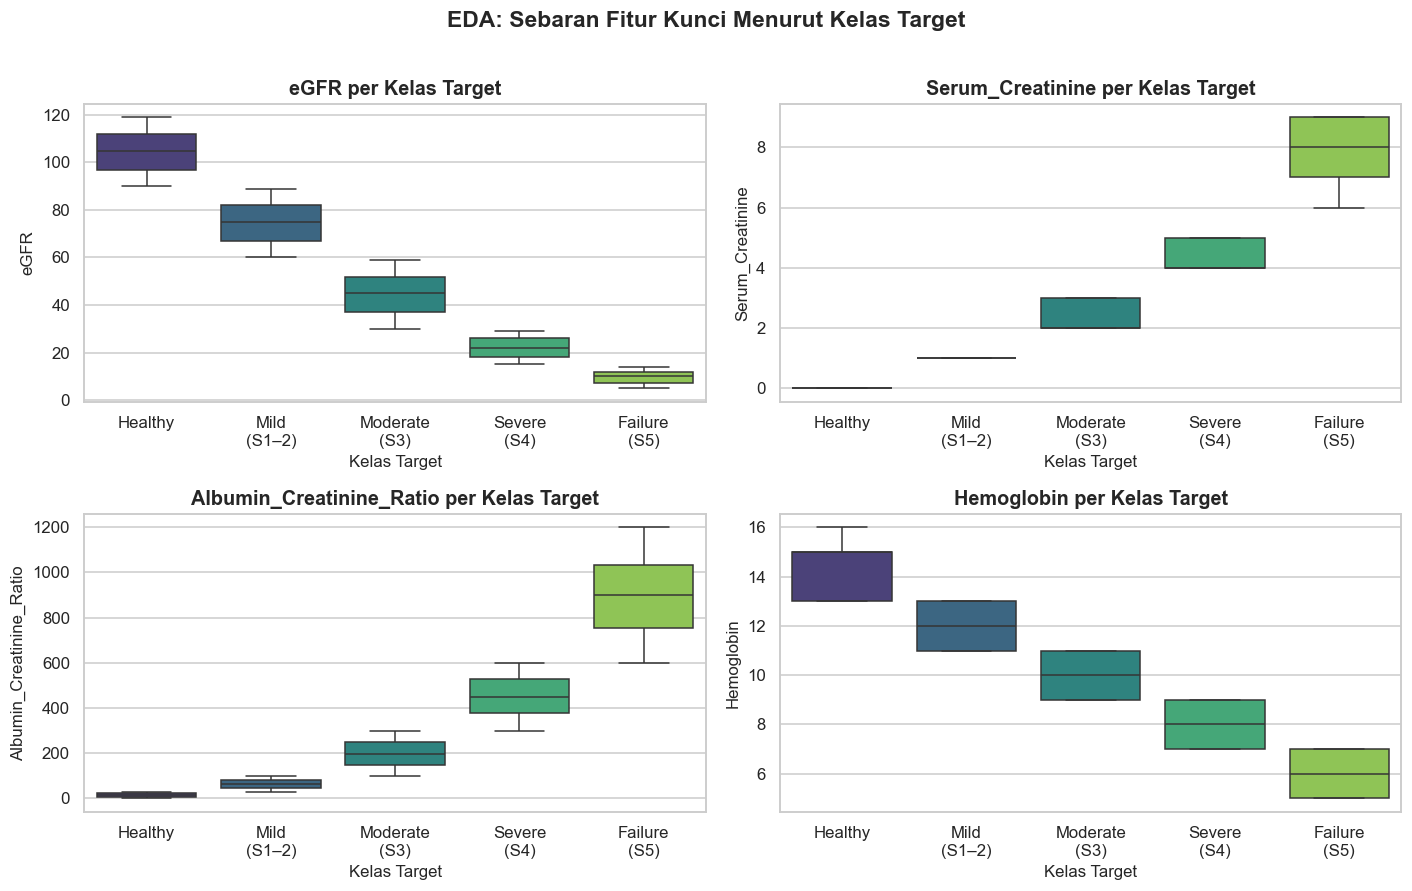

In [15]:
# Perbandingan beberapa fitur kunci antar kelas (boxplot)
key_features = ["eGFR", "Serum_Creatinine", "Albumin_Creatinine_Ratio", "Hemoglobin"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), key_features):
    sns.boxplot(data=df, x="Target", y=col, order=CLASS_ORDER, hue="Target", hue_order=CLASS_ORDER,
                palette="viridis", legend=False, ax=ax, fliersize=2)
    ax.set_title(f"{col} per Kelas Target")
    ax.set_xlabel("Kelas Target")
    ax.set_ylabel(col)
    ax.set_xticks(range(len(CLASS_ORDER)))
    ax.set_xticklabels([SHORT_LABEL[c] for c in CLASS_ORDER])
plt.suptitle("EDA: Sebaran Fitur Kunci Menurut Kelas Target", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 6. Pemeriksaan Missing Values dan Data Duplikat

- **Missing values** diperiksa per kolom. Jika ada, akan ditangani `SimpleImputer` (median untuk numerik, *most frequent* untuk kategorikal).
- **Data duplikat** diperiksa pada seluruh kolom. Baris duplikat yang jatuh di train dan test sekaligus dapat membuat evaluasi terlalu optimis.

Jika dataset ternyata bersih, *pipeline* tetap memasukkan imputer agar **aman terhadap data baru yang memiliki nilai kosong**.

In [16]:
missing = df.isna().sum()
total_missing = int(missing.sum())
print(f"Total missing values : {total_missing}")
if total_missing > 0:
    display(missing[missing > 0].sort_values(ascending=False).rename("jumlah_missing").to_frame())
else:
    print("-> Tidak ada missing values pada dataset ini.")

n_dup = int(df.duplicated().sum())
print(f"\nJumlah baris duplikat : {n_dup}")
if n_dup > 0:
    print("-> Terdapat duplikat; perlu dipertimbangkan sebelum split data.")
else:
    print("-> Tidak ada baris duplikat, sehingga tidak ada risiko baris yang sama muncul di train dan test.")

Total missing values : 0
-> Tidak ada missing values pada dataset ini.

Jumlah baris duplikat : 0
-> Tidak ada baris duplikat, sehingga tidak ada risiko baris yang sama muncul di train dan test.


## 7. Analisis Distribusi Target

Distribusi kelas menentukan cara kita membaca hasil evaluasi. Bila satu kelas sangat dominan, *accuracy* saja bisa menyesatkan: model yang selalu menebak kelas mayoritas pun tampak akurat. Karena itu evaluasi akhir akan menekankan **recall dan F1 per kelas**, *balanced accuracy*, dan *macro average*.

,jumlah,persentase (%)
Target,,
Healthy Kidney,19359,75.03
Mild CKD (Stage 1–2),3066,11.88
Moderate CKD (Stage 3),1807,7.00
Severe CKD (Stage 4),1052,4.08
Kidney Failure (Stage 5),516,2.00


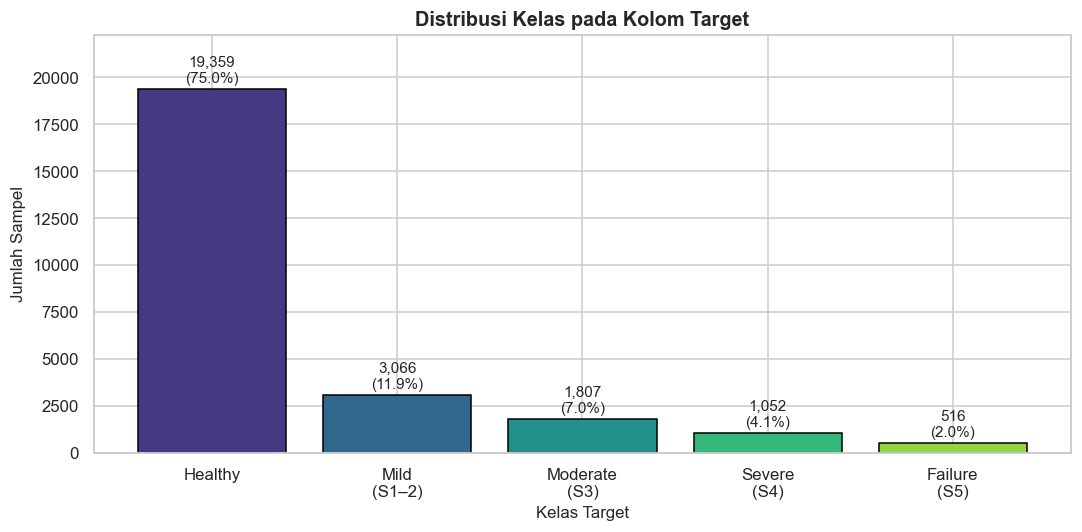

Kelas mayoritas : Healthy Kidney (75.03%)
Rasio mayoritas : minoritas = 37.5 : 1
-> Model 'tebak kelas mayoritas saja' sudah mencapai accuracy 75.03%. Ini baseline yang harus dilampaui, sekaligus alasan mengapa accuracy saja tidak cukup.


In [17]:
class_counts = df["Target"].value_counts().reindex(CLASS_ORDER)
class_table = pd.DataFrame({"jumlah": class_counts, "persentase (%)": (class_counts / len(df) * 100).round(2)})
display(class_table)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar([SHORT_LABEL[c] for c in CLASS_ORDER], class_counts.values,
              color=sns.color_palette("viridis", len(CLASS_ORDER)), edgecolor="black")
for b, v in zip(bars, class_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + class_counts.max() * 0.01,
            f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom", fontsize=10)
ax.set_title("Distribusi Kelas pada Kolom Target")
ax.set_xlabel("Kelas Target")
ax.set_ylabel("Jumlah Sampel")
ax.set_ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

majority = class_counts.idxmax()
baseline_acc = class_counts.max() / len(df)
ratio = class_counts.max() / class_counts.min()
print(f"Kelas mayoritas : {majority} ({baseline_acc:.2%})")
print(f"Rasio mayoritas : minoritas = {ratio:.1f} : 1")
print(f"-> Model 'tebak kelas mayoritas saja' sudah mencapai accuracy {baseline_acc:.2%}. "
      f"Ini baseline yang harus dilampaui, sekaligus alasan mengapa accuracy saja tidak cukup.")

## 8. Preprocessing dan Encoding

### 8.1 Pemisahan fitur dan target
`Target` dipisahkan sebagai `y`. Seluruh **35 kolom lainnya** dipakai sebagai kandidat fitur `X` — tidak ada fitur yang dihapus.

### 8.2 Pemeriksaan risiko *target leakage*
*Target leakage* terjadi bila fitur membawa informasi yang secara langsung/definisional sama dengan label. Pada kasus CKD ini perlu kewaspadaan khusus:

- Stadium CKD menurut pedoman klinis (KDIGO) **ditentukan terutama oleh eGFR** (G1 ≥ 90, G2 60–89, G3 30–59, G4 15–29, G5 < 15 mL/min/1,73 m²) dan dilengkapi kategori albuminuria (ACR).
- `eGFR` sendiri **dihitung dari `Serum_Creatinine`**, usia, dan jenis kelamin.
- Maka `eGFR`, `Serum_Creatinine`, dan (sebagian) `Albumin_Creatinine_Ratio` secara klinis sangat dekat dengan **definisi** label. Jika label pada dataset ini dibuat dari fitur-fitur tersebut, model yang sangat akurat bisa jadi hanya "menemukan kembali aturan pelabelan", bukan "memprediksi" stadium dari gejala yang independen.

Sesuai ketentuan tugas, fitur-fitur ini **tetap dipertahankan** pada model utama (tidak dihapus sembarangan). Risiko didokumentasikan di sini, dan pada bagian 14 dilakukan **analisis sensitivitas diagnostik** (bukan model utama) untuk mengukur seberapa besar model bergantung pada fitur-fitur tersebut.

Pemeriksaan berikut memastikan tidak ada kolom turunan/label tersembunyi di dalam `X`, dan melihat seberapa tegas `eGFR` memisahkan kelas.

In [18]:
# Pisahkan fitur (X) dan label (y). Target TIDAK boleh ada di X.
X = df.drop(columns="Target")
y = df["Target"]
assert "Target" not in X.columns
print(f"X: {X.shape}  |  y: {y.shape}  |  jumlah fitur awal: {X.shape[1]}")

# 1) Tidak ada kolom yang namanya mengindikasikan label/turunan label
suspicious = [c for c in X.columns if any(k in c.lower() for k in ["stage", "target", "class", "diagnos", "label"])]
print("Kolom bernama mencurigakan di X:", suspicious if suspicious else "tidak ada")

# 2) Seberapa tegas fitur 'penentu stadium' memisahkan kelas? (min / median / max per kelas)
leak_cols = ["eGFR", "Serum_Creatinine", "Albumin_Creatinine_Ratio"]
leak_view = (df.groupby("Target")[leak_cols].agg(["min", "median", "max"]).reindex(CLASS_ORDER))
display(leak_view)

# 3) Tumpang tindih rentang eGFR antar kelas yang bersebelahan
egfr = df.groupby("Target")["eGFR"].agg(["min", "max"]).reindex(CLASS_ORDER)
print("Tumpang tindih rentang eGFR antar kelas bersebelahan:")
for a, b in zip(CLASS_ORDER[:-1], CLASS_ORDER[1:]):
    overlap = egfr.loc[a, "min"] - egfr.loc[b, "max"]
    status = "TUMPANG TINDIH" if overlap < 0 else "terpisah tegas"
    print(f"  {a:<26} vs {b:<26}: eGFR min({a.split(' (')[0]})={egfr.loc[a,'min']:.0f}, "
          f"max({b.split(' (')[0]})={egfr.loc[b,'max']:.0f} -> {status}")

X: (25800, 35)  |  y: (25800,)  |  jumlah fitur awal: 35
Kolom bernama mencurigakan di X: tidak ada


eGFR             Serum_Creatinine            Albumin_Creatinine_Ratio             
                          min median  max              min median max                      min median   max
Target                                                                                                     
Healthy Kidney             90  105.0  119                0    0.0   0                        0   15.0    29
Mild CKD (Stage 1–2)       60   75.0   89                1    1.0   1                       30   65.0    99
Moderate CKD (Stage 3)     30   45.0   59                2    2.0   3                      100  198.0   299
Severe CKD (Stage 4)       15   22.0   29                4    4.0   5                      300  450.0   599
Kidney Failure (Stage 5)    5   10.0   14                6    8.0   9                      600  898.0  1199

Tumpang tindih rentang eGFR antar kelas bersebelahan:
  Healthy Kidney             vs Mild CKD (Stage 1–2)      : eGFR min(Healthy Kidney)=90, max(Mild CKD)=89 -> terpisah tegas
  Mild CKD (Stage 1–2)       vs Moderate CKD (Stage 3)    : eGFR min(Mild CKD)=60, max(Moderate CKD)=59 -> terpisah tegas
  Moderate CKD (Stage 3)     vs Severe CKD (Stage 4)      : eGFR min(Moderate CKD)=30, max(Severe CKD)=29 -> terpisah tegas
  Severe CKD (Stage 4)       vs Kidney Failure (Stage 5)  : eGFR min(Severe CKD)=15, max(Kidney Failure)=14 -> terpisah tegas


### 8.3 Identifikasi tipe fitur dan pembangunan *Pipeline*

- Fitur **numerik** dan **kategorikal** diidentifikasi **otomatis** berdasarkan tipe data.
- Numerik: `SimpleImputer(strategy="median")`. Kategorikal: `SimpleImputer(strategy="most_frequent")` lalu `OneHotEncoder(handle_unknown="ignore")`.
- Semuanya digabung dengan `ColumnTransformer` dan dibungkus bersama model dalam satu `Pipeline`. Dengan begitu imputer dan encoder **hanya di-*fit* pada data training** (saat `pipeline.fit(X_train, y_train)`), sehingga tidak ada kebocoran dari data testing.
- **Tidak ada `StandardScaler`**: Random Forest berbasis pohon keputusan sehingga tidak sensitif terhadap skala fitur.
- `handle_unknown="ignore"` membuat model aman jika data baru memuat kategori yang belum pernah terlihat.

In [19]:
# Identifikasi tipe fitur secara otomatis
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()
print(f"Fitur numerik     ({len(numeric_features)}): {numeric_features}\n")
print(f"Fitur kategorikal ({len(categorical_features)}): {categorical_features}")


def make_preprocessor(num_cols, cat_cols):
    # Membuat ColumnTransformer: imputasi + one-hot encoding (tanpa scaling).
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([("num", numeric_pipe, num_cols),
                              ("cat", categorical_pipe, cat_cols)])


def build_pipeline(drop=(), **rf_params):
    # Pipeline lengkap: preprocessing + RandomForest.
    # 'drop' hanya dipakai untuk analisis sensitivitas diagnostik; model utama memakai semua 35 fitur.
    num = [c for c in numeric_features if c not in drop]
    cat = [c for c in categorical_features if c not in drop]
    rf = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **rf_params)
    return Pipeline([("preprocessor", make_preprocessor(num, cat)), ("model", rf)])


build_pipeline()   # tampilkan struktur pipeline

Fitur numerik     (31): ['Age', 'Gender', 'BMI', 'Systolic_BP', 'Diastolic_BP', 'Heart_Rate', 'Serum_Creatinine', 'Blood_Urea_Nitrogen', 'eGFR', 'Urine_Albumin', 'Urine_Protein', 'Albumin_Creatinine_Ratio', 'Urine_Specific_Gravity', 'Sodium', 'Potassium', 'Calcium', 'Phosphorus', 'Chloride', 'Bicarbonate', 'Hemoglobin', 'RBC_Count', 'WBC_Count', 'Platelet_Count', 'Packed_Cell_Volume', 'Blood_Glucose_Random', 'Fasting_Glucose', 'HbA1c', 'Cholesterol', 'Triglycerides', 'Serum_Albumin', 'Total_Protein']

Fitur kategorikal (4): ['Diabetes', 'Hypertension', 'Smoking_Status', 'Family_History_Kidney']


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 9. Split Data 80:20

Data dibagi 80% training dan 20% testing dengan `random_state=42` dan **`stratify=y`**, sehingga proporsi setiap kelas di data training dan testing sama dengan proporsi aslinya. Hal ini penting untuk kelas minoritas (mis. Stage 5) agar tetap terwakili pada data uji.

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"Data training : {X_train.shape[0]:,} baris  ({X_train.shape[0] / len(X):.0%})")
print(f"Data testing  : {X_test.shape[0]:,} baris  ({X_test.shape[0] / len(X):.0%})\n")

split_check = pd.DataFrame({
    "total (%)": (y.value_counts(normalize=True) * 100).reindex(CLASS_ORDER),
    "train (%)": (y_train.value_counts(normalize=True) * 100).reindex(CLASS_ORDER),
    "test (%)": (y_test.value_counts(normalize=True) * 100).reindex(CLASS_ORDER),
    "jumlah test": y_test.value_counts().reindex(CLASS_ORDER)}).round(2)
display(split_check)

Data training : 20,640 baris  (80%)
Data testing  : 5,160 baris  (20%)



,total (%),train (%),test (%),jumlah test
Target,,,,
Healthy Kidney,75.03,75.03,75.04,3872
Mild CKD (Stage 1–2),11.88,11.88,11.88,613
Moderate CKD (Stage 3),7.00,7.01,7.00,361
Severe CKD (Stage 4),4.08,4.07,4.09,211
Kidney Failure (Stage 5),2.00,2.00,2.00,103


### 9.1 Diagnostik separabilitas fitur tunggal (pemeriksaan *target leakage* berbasis data)

Untuk menguji kecurigaan pada bagian 8.2 secara empiris, setiap fitur numerik dilatih **sendirian** (Random Forest kecil: 20 pohon, `max_depth=6`) pada data training lalu diuji pada data testing. Jika **satu fitur saja** sudah menghasilkan akurasi mendekati 100%, maka label hampir sepenuhnya ditentukan oleh fitur itu, entah karena label diturunkan dari fitur tersebut atau karena data dibangkitkan dengan rentang nilai per kelas yang tidak tumpang tindih. Baseline pembanding adalah akurasi tebak kelas mayoritas.

Ini murni **diagnostik** (bukan pemilihan model dan bukan perbandingan algoritma).

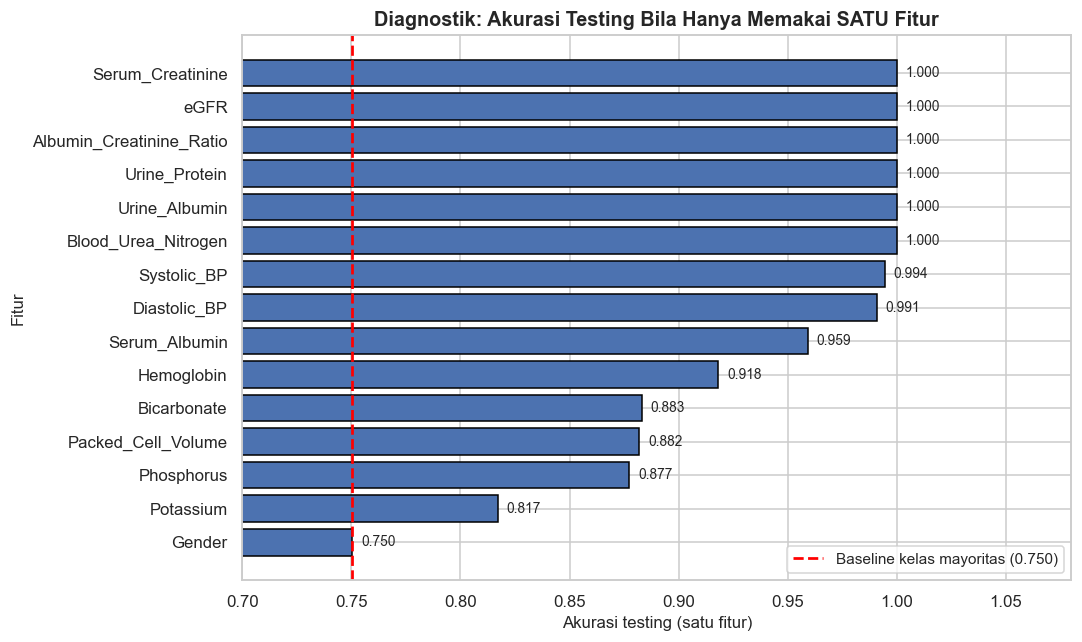

**Temuan diagnostik:** **6** fitur masing-masing mencapai akurasi >= 99,9% hanya dengan dirinya sendiri (`Serum_Creatinine`, `eGFR`, `Albumin_Creatinine_Ratio`, `Urine_Protein`, `Urine_Albumin`, `Blood_Urea_Nitrogen`); total **9** fitur >= 95%. Ini adalah **tanda kuat target leakage / keterpisahan sempurna**: label dapat direkonstruksi dari satu penanda tunggal, sehingga akurasi model yang sangat tinggi nantinya **tidak boleh dibaca** sebagai bukti kemampuan klinis yang sebenarnya.

In [21]:
single_rows = []
for col in numeric_features:
    m = RandomForestClassifier(n_estimators=20, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1)
    m.fit(X_train[[col]], y_train)
    single_rows.append({"fitur": col, "akurasi_fitur_tunggal": accuracy_score(y_test, m.predict(X_test[[col]]))})
single_feat = (pd.DataFrame(single_rows).sort_values("akurasi_fitur_tunggal", ascending=False).reset_index(drop=True))

top_single = single_feat.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_single["fitur"], top_single["akurasi_fitur_tunggal"], color="#4c72b0", edgecolor="black")
ax.axvline(baseline_acc, color="red", ls="--", lw=1.8, label=f"Baseline kelas mayoritas ({baseline_acc:.3f})")
for i, v in enumerate(top_single["akurasi_fitur_tunggal"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0.7, 1.08)
ax.set_title("Diagnostik: Akurasi Testing Bila Hanya Memakai SATU Fitur")
ax.set_xlabel("Akurasi testing (satu fitur)")
ax.set_ylabel("Fitur")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

near_perfect = single_feat.loc[single_feat["akurasi_fitur_tunggal"] >= 0.999, "fitur"].tolist()
strong = single_feat.loc[single_feat["akurasi_fitur_tunggal"] >= 0.95, "fitur"].tolist()
display(Markdown(
    f"**Temuan diagnostik:** **{len(near_perfect)}** fitur masing-masing mencapai akurasi >= 99,9% hanya dengan dirinya sendiri "
    f"({', '.join('`'+f+'`' for f in near_perfect) if near_perfect else '-'}); total **{len(strong)}** fitur >= 95%. "
    + ("Ini adalah **tanda kuat target leakage / keterpisahan sempurna**: label dapat direkonstruksi dari satu penanda tunggal, "
       "sehingga akurasi model yang sangat tinggi nantinya **tidak boleh dibaca** sebagai bukti kemampuan klinis yang sebenarnya."
       if near_perfect else "Tidak ada fitur tunggal yang hampir sempurna, sehingga indikasi leakage tunggal tidak ditemukan.")))

## 10. Skenario A — Pengaruh Jumlah Pohon (`n_estimators`)

Random Forest menggabungkan banyak pohon keputusan (*bagging* + pemilihan fitur acak). Secara teori, menambah jumlah pohon **menurunkan varians** prediksi sehingga hasil lebih stabil, tetapi keuntungannya makin kecil setelah jumlah tertentu (*diminishing returns*), sementara waktu pelatihan terus naik.

Eksperimen: `n_estimators = [10, 50, 100, 200, 500]`, parameter lain default (`max_depth=None`), `random_state=42`. Untuk tiap konfigurasi dicatat akurasi training/testing, selisihnya (*gap*), *balanced accuracy*, *macro F1*, dan **recall kelas terlemah** — agar kualitas pada kelas minoritas ikut terpantau.

In [22]:
def fit_and_score(params, drop=()):
    # Latih satu pipeline dan kumpulkan metrik train/test + ukuran kompleksitas pohon.
    t0 = time.time()
    pipe = build_pipeline(drop=drop, **params)
    pipe.fit(X_train, y_train)                       # imputer/encoder di-fit HANYA pada data train
    pred_tr, pred_te = pipe.predict(X_train), pipe.predict(X_test)
    forest = pipe.named_steps["model"]
    return {
        "train_acc": accuracy_score(y_train, pred_tr),
        "test_acc": accuracy_score(y_test, pred_te),
        "gap": accuracy_score(y_train, pred_tr) - accuracy_score(y_test, pred_te),
        "test_bal_acc": balanced_accuracy_score(y_test, pred_te),
        "test_macro_f1": f1_score(y_test, pred_te, average="macro"),
        "min_class_recall": recall_score(y_test, pred_te, average=None, labels=CLASS_ORDER).min(),
        "test_log_loss": log_loss(y_test, pipe.predict_proba(X_test), labels=pipe.classes_),
        "max_tree_depth": int(max(t.get_depth() for t in forest.estimators_)),
        "avg_tree_depth": float(np.mean([t.get_depth() for t in forest.estimators_])),
        "avg_leaves": float(np.mean([t.get_n_leaves() for t in forest.estimators_])),
        "fit_sec": time.time() - t0,
        "recall_by_class": recall_score(y_test, pred_te, average=None, labels=CLASS_ORDER),
    }


n_estimators_list = [10, 50, 100, 200, 500]
rows_A = []
for n in n_estimators_list:
    res = fit_and_score({"n_estimators": n})
    rows_A.append({"n_estimators": n, **res})
    print(f"n_estimators={n:<4} | train={res['train_acc']:.4f} | test={res['test_acc']:.4f} | "
          f"waktu={res['fit_sec']:.1f}s")

results_A = pd.DataFrame(rows_A)
results_A["delta_test_acc"] = results_A["test_acc"].diff()
print("\nTabel hasil Skenario A:")
display(results_A.drop(columns="recall_by_class").round(4))

n_estimators=10   | train=1.0000 | test=1.0000 | waktu=0.7s
n_estimators=50   | train=1.0000 | test=1.0000 | waktu=0.8s
n_estimators=100  | train=1.0000 | test=1.0000 | waktu=1.3s
n_estimators=200  | train=1.0000 | test=1.0000 | waktu=1.8s
n_estimators=500  | train=1.0000 | test=1.0000 | waktu=3.9s

Tabel hasil Skenario A:


,n_estimators,train_acc,test_acc,gap,test_bal_acc,test_macro_f1,min_class_recall,test_log_loss,max_tree_depth,avg_tree_depth,avg_leaves,fit_sec,delta_test_acc
0,10,1.0,1.0,0.0,1.0,1.0,1.0,0.0,5,4.20,6.100,0.6859,NaN
1,50,1.0,1.0,0.0,1.0,1.0,1.0,0.0,8,4.58,6.740,0.7977,0.0
2,100,1.0,1.0,0.0,1.0,1.0,1.0,0.0,8,4.65,6.830,1.2638,0.0
3,200,1.0,1.0,0.0,1.0,1.0,1.0,0.0,9,4.62,6.925,1.7505,0.0
4,500,1.0,1.0,0.0,1.0,1.0,1.0,0.0,9,4.66,6.840,3.8999,0.0


## 11. Visualisasi dan Analisis Skenario A

Grafik kiri menampilkan **akurasi testing** terhadap jumlah pohon (sesuai ketentuan). Grafik kanan melengkapinya dengan *balanced accuracy* dan *macro F1* agar terlihat apakah perbaikan juga terjadi pada kelas minoritas.

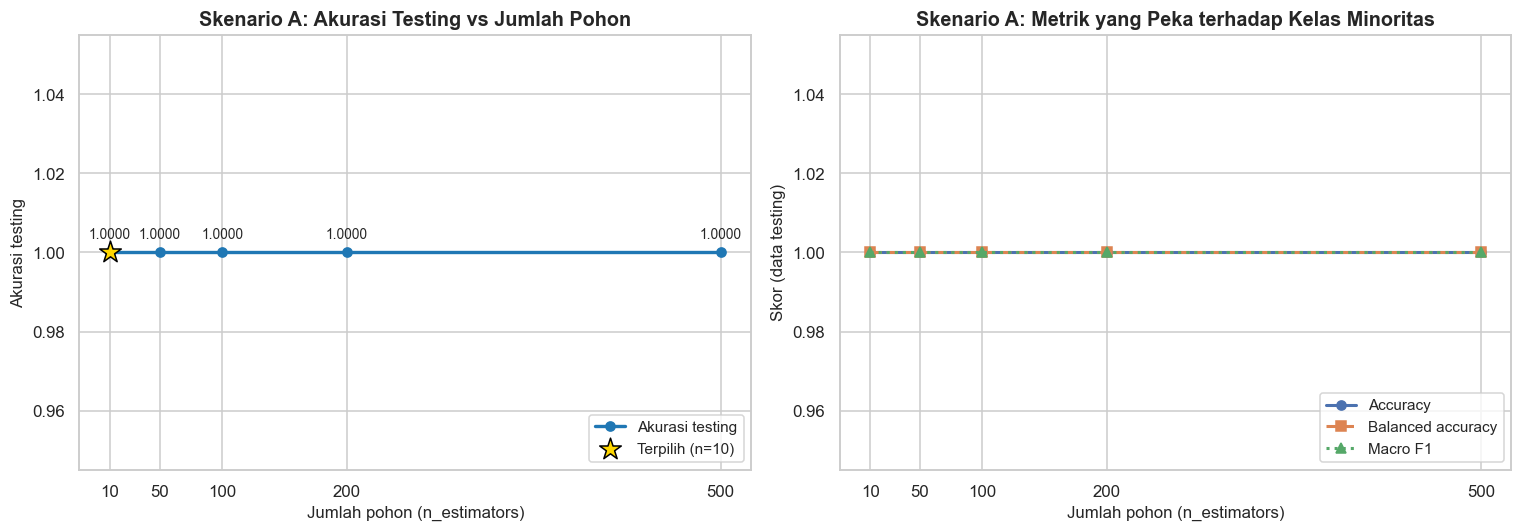

### Analisis otomatis Skenario A
- Akurasi testing **identik di semua variasi jumlah pohon** (**1.0000** pada 10 hingga 500 pohon). Menambah pohon **tidak mengubah akurasi sama sekali**.
- Ini terjadi karena data sangat mudah dipisahkan (lihat diagnostik 9.1): bahkan 10 pohon sudah cukup untuk memetakan semua kelas, sehingga pengurangan varians yang biasanya diberikan pohon tambahan tidak punya ruang untuk memperbaiki akurasi (efek *saturasi/ceiling*). Kedalaman aktual rata-rata pohon hanya ±4.5 level.
- Yang berubah hanya **biaya**: waktu pelatihan naik sekitar **5.7x** (dari 0.7 dtk ke 3.9 dtk), dan log loss testing bergerak dari 0.0000 ke 0.0000.
- **Konfigurasi terbaik:** akurasi testing tertinggi = 1.0000 (pertama dicapai pada n = 10). Dengan aturan 'konfigurasi dalam toleransi 0.001 -> pilih log loss testing terendah -> lalu paling sedikit pohon', terpilih **n_estimators = 10** (test acc 1.0000, balanced acc 1.0000, macro F1 1.0000, log loss 0.0000).

In [23]:
# Aturan pemilihan: akurasi testing tertinggi. Jika beberapa konfigurasi hanya berbeda <= TOL_A,
# bandingkan log loss testing (lebih rendah = probabilitas lebih yakin & tepat), lalu pilih yang paling sederhana.
TOL_A = 0.001
max_acc_A = results_A["test_acc"].max()
argmax_n = int(results_A.loc[results_A["test_acc"].idxmax(), "n_estimators"])
cand_A = results_A[results_A["test_acc"] >= max_acc_A - TOL_A].assign(ll=lambda d: d["test_log_loss"].round(4))
best_n = int(cand_A.sort_values(["ll", "n_estimators"]).iloc[0]["n_estimators"])
best_row = results_A[results_A["n_estimators"] == best_n].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(results_A["n_estimators"], results_A["test_acc"], marker="o", lw=2.2, color="#1f77b4", label="Akurasi testing")
for x_, y_ in zip(results_A["n_estimators"], results_A["test_acc"]):
    ax.annotate(f"{y_:.4f}", (x_, y_), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.scatter([best_n], [best_row["test_acc"]], s=220, marker="*", color="gold", edgecolor="black", zorder=5,
           label=f"Terpilih (n={best_n})")
ax.set_xticks(n_estimators_list)
ax.set_title("Skenario A: Akurasi Testing vs Jumlah Pohon")
ax.set_xlabel("Jumlah pohon (n_estimators)")
ax.set_ylabel("Akurasi testing")
ax.legend(loc="lower right")

ax = axes[1]
ax.plot(results_A["n_estimators"], results_A["test_acc"], marker="o", lw=2, label="Accuracy")
ax.plot(results_A["n_estimators"], results_A["test_bal_acc"], marker="s", lw=2, ls="--", label="Balanced accuracy")
ax.plot(results_A["n_estimators"], results_A["test_macro_f1"], marker="^", lw=2, ls=":", label="Macro F1")
ax.set_xticks(n_estimators_list)
ax.set_title("Skenario A: Metrik yang Peka terhadap Kelas Minoritas")
ax.set_xlabel("Jumlah pohon (n_estimators)")
ax.set_ylabel("Skor (data testing)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ----- Analisis otomatis (bercabang: akurasi berubah vs. akurasi identik/jenuh) -----
first, last = results_A.iloc[0], results_A.iloc[-1]
spread_A = results_A["test_acc"].max() - results_A["test_acc"].min()
time_ratio = last["fit_sec"] / first["fit_sec"]
text = ["### Analisis otomatis Skenario A"]
if spread_A < 1e-9:
    text += [f"- Akurasi testing **identik di semua variasi jumlah pohon** (**{first['test_acc']:.4f}** pada 10 hingga 500 pohon). "
             f"Menambah pohon **tidak mengubah akurasi sama sekali**.",
             f"- Ini terjadi karena data sangat mudah dipisahkan (lihat diagnostik 9.1): bahkan 10 pohon sudah cukup untuk memetakan semua kelas, "
             f"sehingga pengurangan varians yang biasanya diberikan pohon tambahan tidak punya ruang untuk memperbaiki akurasi (efek *saturasi/ceiling*). "
             f"Kedalaman aktual rata-rata pohon hanya ±{results_A['avg_tree_depth'].mean():.1f} level.",
             f"- Yang berubah hanya **biaya**: waktu pelatihan naik sekitar **{time_ratio:.1f}x** (dari {first['fit_sec']:.1f} dtk ke {last['fit_sec']:.1f} dtk), "
             f"dan log loss testing bergerak dari {first['test_log_loss']:.4f} ke {last['test_log_loss']:.4f}."]
else:
    gain_total = last["test_acc"] - first["test_acc"]
    biggest = results_A.iloc[1:].loc[results_A.iloc[1:]["delta_test_acc"].idxmax()]
    plateau_n = next((int(results_A["n_estimators"].iloc[i]) for i in range(len(results_A))
                      if results_A["test_acc"].iloc[i:].max() - results_A["test_acc"].iloc[i:].min() <= TOL_A), None)
    text += [f"- Dari **{int(first['n_estimators'])}** ke **{int(last['n_estimators'])}** pohon, akurasi testing berubah dari "
             f"**{first['test_acc']:.4f}** ke **{last['test_acc']:.4f}** ({gain_total*100:+.2f} poin persentase).",
             f"- Peningkatan terbesar terjadi pada langkah menuju **{int(biggest['n_estimators'])}** pohon ({biggest['delta_test_acc']:+.4f}).",
             f"- Waktu pelatihan naik sekitar **{time_ratio:.1f}x**."]
    if plateau_n is not None:
        text.append(f"- Akurasi relatif stabil mulai ±{plateau_n} pohon (variasi setelahnya <= {TOL_A:.3f}), tanda *diminishing returns*.")
text.append(f"- **Konfigurasi terbaik:** akurasi testing tertinggi = {max_acc_A:.4f} (pertama dicapai pada n = {argmax_n}). "
            f"Dengan aturan 'konfigurasi dalam toleransi {TOL_A:.3f} -> pilih log loss testing terendah -> lalu paling sedikit pohon', "
            f"terpilih **n_estimators = {best_n}** (test acc {best_row['test_acc']:.4f}, balanced acc {best_row['test_bal_acc']:.4f}, "
            f"macro F1 {best_row['test_macro_f1']:.4f}, log loss {best_row['test_log_loss']:.4f}).")
display(Markdown("\n".join(text)))

## 12. Skenario B — Pengaruh Kedalaman Pohon (`max_depth`)

`max_depth` membatasi seberapa dalam pohon boleh tumbuh, sehingga mengontrol **kompleksitas model**:

- **Terlalu dangkal** → pohon tidak cukup mampu menangkap pola → *underfitting* (akurasi rendah di training **dan** testing).
- **Sangat dalam / tanpa batas (`None`)** → pohon bisa menghafal data training → akurasi training sangat tinggi dan selisih train–test dapat melebar.

> ⚠️ Akurasi training tinggi **belum otomatis berarti overfitting**. Pada Random Forest, pohon tanpa batas hampir selalu mencapai akurasi training ≈ 100% karena data training masuk ke dalam *bootstrap* masing-masing pohon. Yang menentukan adalah apakah **performa testing ikut membaik atau memburuk** dan bagaimana hasil per kelas.

Eksperimen memakai `n_estimators` terbaik dari Skenario A, dengan `max_depth = [None, 3, 5, 10, 20]`.

In [24]:
depth_options = {"None": None, "3": 3, "5": 5, "10": 10, "20": 20}   # label -> nilai parameter
rows_B = []
for label, depth in depth_options.items():
    res = fit_and_score({"n_estimators": best_n, "max_depth": depth})
    rows_B.append({"max_depth": label, **res})
    print(f"max_depth={label:<5} | train={res['train_acc']:.4f} | test={res['test_acc']:.4f} | "
          f"gap={res['gap']:.4f} | rata2 kedalaman pohon={res['avg_tree_depth']:.1f}")

results_B = pd.DataFrame(rows_B)
print(f"\nTabel hasil Skenario B (n_estimators = {best_n}):")
display(results_B.drop(columns="recall_by_class").round(4))

max_depth=None  | train=1.0000 | test=1.0000 | gap=0.0000 | rata2 kedalaman pohon=4.2
max_depth=3     | train=0.9800 | test=0.9800 | gap=-0.0000 | rata2 kedalaman pohon=3.0
max_depth=5     | train=1.0000 | test=1.0000 | gap=0.0000 | rata2 kedalaman pohon=4.2
max_depth=10    | train=1.0000 | test=1.0000 | gap=0.0000 | rata2 kedalaman pohon=4.2
max_depth=20    | train=1.0000 | test=1.0000 | gap=0.0000 | rata2 kedalaman pohon=4.2

Tabel hasil Skenario B (n_estimators = 10):


,max_depth,train_acc,test_acc,gap,test_bal_acc,test_macro_f1,min_class_recall,test_log_loss,max_tree_depth,avg_tree_depth,avg_leaves,fit_sec
0,None,1.00,1.00,0.0,1.0,1.0000,1.0,0.0000,5,4.2,6.1,0.4752
1,3,0.98,0.98,-0.0,0.8,0.7608,0.0,0.0516,3,3.0,4.2,0.5615
2,5,1.00,1.00,0.0,1.0,1.0000,1.0,0.0000,5,4.2,6.1,0.6342
3,10,1.00,1.00,0.0,1.0,1.0000,1.0,0.0000,5,4.2,6.1,0.5636
4,20,1.00,1.00,0.0,1.0,1.0000,1.0,0.0000,5,4.2,6.1,0.4273


## 13. Visualisasi dan Analisis Skenario B

Grafik kiri membandingkan **akurasi training vs testing** untuk tiap kedalaman (urut dari paling dangkal ke tanpa batas); area di antara dua garis adalah *gap*. Grafik kanan menunjukkan **kedalaman aktual rata-rata pohon** sebagai ukuran kompleksitas model.

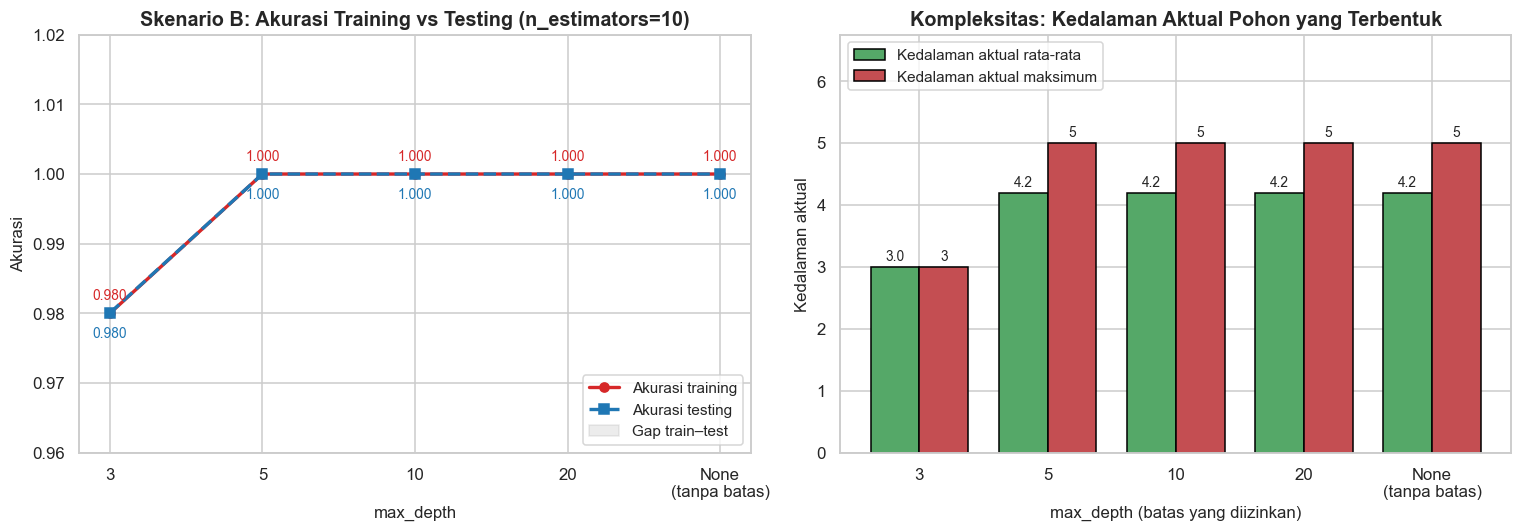

Recall per kelas (data testing) untuk tiap max_depth:


,Healthy,Mild (S1–2),Moderate (S3),Severe (S4),Failure (S5)
max_depth,,,,,
3,1.0,1.0,1.0,1.0,0.0
5,1.0,1.0,1.0,1.0,1.0
10,1.0,1.0,1.0,1.0,1.0
20,1.0,1.0,1.0,1.0,1.0
None,1.0,1.0,1.0,1.0,1.0


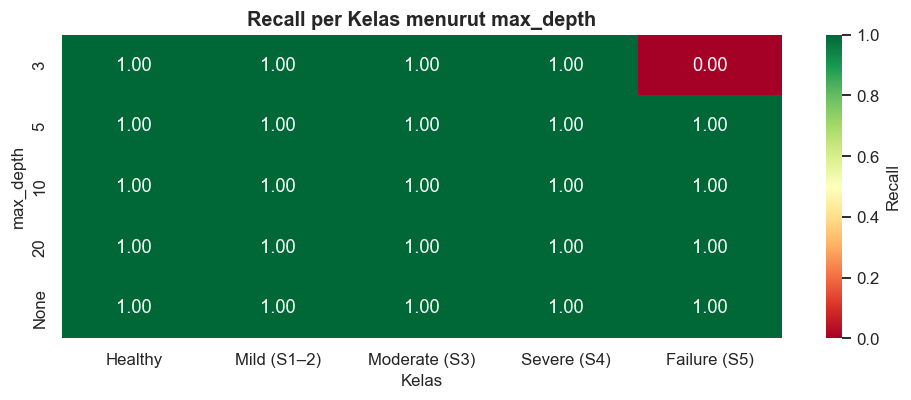

,max_depth,train_acc,test_acc,gap,min_class_recall,test_log_loss,max_tree_depth,diagnosis
0,None,1.00,1.00,0.0,1.0,0.0000,5,"Seimbang (gap kecil, semua kelas dikenali deng..."
1,3,0.98,0.98,-0.0,0.0,0.0516,3,"Indikasi UNDERFITTING: gap kecil, tetapi kelas..."
2,5,1.00,1.00,0.0,1.0,0.0000,5,"Seimbang (gap kecil, semua kelas dikenali deng..."
3,10,1.00,1.00,0.0,1.0,0.0000,5,"Seimbang (gap kecil, semua kelas dikenali deng..."
4,20,1.00,1.00,0.0,1.0,0.0000,5,"Seimbang (gap kecil, semua kelas dikenali deng..."


### Analisis otomatis Skenario B
- **Kompleksitas:** tanpa batas (`None`), pohon hanya tumbuh sampai kedalaman maksimum **5** (rata-rata 4.2) lalu berhenti sendiri karena semua daun sudah murni. Dengan `max_depth=3` kedalaman rata-rata 3.0 dan jumlah daun rata-rata 4.2 (vs 6.1).
- Batas `max_depth` = 10, 20 **tidak pernah tercapai** (pohon berhenti sebelum batas), sehingga model-model tersebut praktis **identik** dengan `None` — hasilnya sama persis bukan kebetulan.
- **Underfitting pada `max_depth=3`:** accuracy 0.9800 tampak tinggi, tetapi balanced accuracy hanya 0.8000, macro F1 0.7608, dan recall kelas **Kidney Failure (Stage 5)** = 0.00. Pohon sedalam 3 level tidak cukup kapasitas untuk memisahkan lima kelas (rata-rata hanya 4.2 daun), sehingga kelas terkecil tidak pernah diprediksi. Inilah alasan accuracy saja menyesatkan pada data tidak seimbang.
- **Overfitting:** gap train–test pada seluruh konfigurasi adalah -0.0000 s.d. +0.0000. Tidak ada konfigurasi dengan gap besar sehingga **tidak ditemukan indikasi overfitting**; akurasi training 100% pada model dalam di sini disertai akurasi testing yang sama tingginya, jadi bukan bukti menghafal.
- **Konfigurasi terbaik:** `max_depth = 5` (test acc 1.0000, gap 0.0000, recall kelas terlemah 1.0000). Aturan: akurasi dalam 0.002 dari yang tertinggi dan semua kelas dikenali, lalu gap terkecil, log loss terendah, dan paling sederhana.

In [25]:
# Urutan tampilan dari paling sederhana ke paling kompleks
plot_order = ["3", "5", "10", "20", "None"]
rb = results_B.set_index("max_depth").loc[plot_order].reset_index()
xlabels = [l if l != "None" else "None\n(tanpa batas)" for l in rb["max_depth"]]
xpos = np.arange(len(rb))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(xpos, rb["train_acc"], marker="o", lw=2.2, color="#d62728", label="Akurasi training")
ax.plot(xpos, rb["test_acc"], marker="s", lw=2.2, ls="--", color="#1f77b4", label="Akurasi testing")
ax.fill_between(xpos, rb["test_acc"], rb["train_acc"], color="gray", alpha=0.15, label="Gap train–test")
for i, rr in rb.iterrows():
    ax.annotate(f"{rr['train_acc']:.3f}", (i, rr["train_acc"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color="#d62728")
    ax.annotate(f"{rr['test_acc']:.3f}", (i, rr["test_acc"]), textcoords="offset points", xytext=(0, -16), ha="center", fontsize=9, color="#1f77b4")
ax.set_xticks(xpos); ax.set_xticklabels(xlabels)
ax.set_title(f"Skenario B: Akurasi Training vs Testing (n_estimators={best_n})")
ax.set_xlabel("max_depth")
ax.set_ylabel("Akurasi")
ax.set_ylim(min(rb["test_acc"].min(), rb["train_acc"].min()) - 0.02, 1.02)
ax.legend(loc="lower right")

ax = axes[1]
w = 0.38
ax.bar(xpos - w / 2, rb["avg_tree_depth"], w, color="#55a868", edgecolor="black", label="Kedalaman aktual rata-rata")
ax.bar(xpos + w / 2, rb["max_tree_depth"], w, color="#c44e52", edgecolor="black", label="Kedalaman aktual maksimum")
for i, (a_, m_) in enumerate(zip(rb["avg_tree_depth"], rb["max_tree_depth"])):
    ax.text(i - w / 2, a_ + 0.1, f"{a_:.1f}", ha="center", fontsize=9)
    ax.text(i + w / 2, m_ + 0.1, f"{m_}", ha="center", fontsize=9)
ax.set_xticks(xpos); ax.set_xticklabels(xlabels)
ax.set_title("Kompleksitas: Kedalaman Aktual Pohon yang Terbentuk")
ax.set_xlabel("max_depth (batas yang diizinkan)")
ax.set_ylabel("Kedalaman aktual")
ax.set_ylim(0, rb["max_tree_depth"].max() * 1.35)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

# ----- Recall per kelas untuk tiap kedalaman (agar kelas minoritas tidak tersembunyi di balik accuracy) -----
recall_B = pd.DataFrame(np.vstack(results_B["recall_by_class"].values), index=results_B["max_depth"],
                        columns=[SHORT_LABEL[c].replace("\n", " ") for c in CLASS_ORDER]).loc[plot_order]
recall_B.index.name = "max_depth"
print("Recall per kelas (data testing) untuk tiap max_depth:")
display(recall_B.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(recall_B, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "Recall"}, ax=ax)
ax.set_title("Recall per Kelas menurut max_depth")
ax.set_xlabel("Kelas")
ax.set_ylabel("max_depth")
plt.tight_layout()
plt.show()

# ----- Diagnosis fit per konfigurasi -----
best_test_B = results_B["test_acc"].max()
def diagnose(rw):
    rec = np.asarray(rw["recall_by_class"])
    worst_cls = SHORT_LABEL[CLASS_ORDER[int(rec.argmin())]].replace("\n", " ")
    if rec.min() < 0.5 and rw["gap"] < 0.02:
        return (f"Indikasi UNDERFITTING: gap kecil, tetapi kelas '{worst_cls}' hampir tidak dikenali "
                f"(recall {rec.min():.2f}); accuracy tinggi menyembunyikannya karena kelas ini kecil")
    if rw["test_acc"] < best_test_B - 0.01:
        return "Indikasi UNDERFITTING: performa train dan test sama-sama di bawah yang terbaik"
    if rw["gap"] > 0.05 and rw["test_acc"] < best_test_B - 0.005:
        return "Indikasi OVERFITTING: gap besar DAN test lebih rendah dari konfigurasi terbaik"
    if rw["gap"] > 0.05:
        return "Gap besar, tetapi test kompetitif -> bukan overfitting yang merugikan"
    return "Seimbang (gap kecil, semua kelas dikenali dengan baik)"
results_B["diagnosis"] = results_B.apply(diagnose, axis=1)
display(results_B[["max_depth", "train_acc", "test_acc", "gap", "min_class_recall", "test_log_loss", "max_tree_depth", "diagnosis"]].round(4))

# ----- Pemilihan max_depth terbaik -----
# Kandidat: test acc dalam TOL_B dari yang tertinggi DAN semua kelas dikenali (min recall >= 0.5).
# Dari kandidat pilih gap terkecil (stabil), lalu log loss terendah, lalu yang lebih dangkal (lebih sederhana).
TOL_B = 0.002
order_map = {"3": 0, "5": 1, "10": 2, "20": 3, "None": 4}
cand_B = results_B[(results_B["test_acc"] >= best_test_B - TOL_B) & (results_B["min_class_recall"] >= 0.5)].copy()
cand_B["order"] = cand_B["max_depth"].map(order_map)
cand_B["gap_r"], cand_B["ll_r"] = cand_B["gap"].round(4), cand_B["test_log_loss"].round(4)
chosen = cand_B.sort_values(["gap_r", "ll_r", "order"]).iloc[0]
best_depth_label = chosen["max_depth"]
best_depth = depth_options[best_depth_label]

# Batas kedalaman yang 'mengikat' = benar-benar menghentikan pertumbuhan pohon
def binding(lbl):
    lim = depth_options[lbl]
    return lim is not None and results_B.set_index("max_depth").loc[lbl, "max_tree_depth"] >= lim
free_depth = int(results_B.set_index("max_depth").loc["None", "max_tree_depth"])
not_binding = [l for l in ["5", "10", "20"] if not binding(l)]
shallow = results_B.set_index("max_depth").loc["3"]; deep = results_B.set_index("max_depth").loc["None"]
worst_cls3 = CLASS_ORDER[int(np.asarray(shallow["recall_by_class"]).argmin())]

text = ["### Analisis otomatis Skenario B",
        f"- **Kompleksitas:** tanpa batas (`None`), pohon hanya tumbuh sampai kedalaman maksimum **{free_depth}** "
        f"(rata-rata {deep['avg_tree_depth']:.1f}) lalu berhenti sendiri karena semua daun sudah murni. Dengan `max_depth=3` kedalaman rata-rata {shallow['avg_tree_depth']:.1f} "
        f"dan jumlah daun rata-rata {shallow['avg_leaves']:.1f} (vs {deep['avg_leaves']:.1f}).",
        (f"- Batas `max_depth` = {', '.join(not_binding)} **tidak pernah tercapai** (pohon berhenti sebelum batas), sehingga model-model tersebut praktis "
         f"**identik** dengan `None` — hasilnya sama persis bukan kebetulan." if not_binding else "- Semua batas kedalaman membatasi pertumbuhan pohon."),
        f"- **Underfitting pada `max_depth=3`:** accuracy {shallow['test_acc']:.4f} tampak tinggi, tetapi balanced accuracy hanya {shallow['test_bal_acc']:.4f}, "
        f"macro F1 {shallow['test_macro_f1']:.4f}, dan recall kelas **{worst_cls3}** = {np.asarray(shallow['recall_by_class']).min():.2f}. "
        f"Pohon sedalam 3 level tidak cukup kapasitas untuk memisahkan lima kelas (rata-rata hanya {shallow['avg_leaves']:.1f} daun), "
        f"sehingga kelas terkecil tidak pernah diprediksi. Inilah alasan accuracy saja menyesatkan pada data tidak seimbang.",
        f"- **Overfitting:** gap train–test pada seluruh konfigurasi adalah {results_B['gap'].min():+.4f} s.d. {results_B['gap'].max():+.4f}. "
        f"Tidak ada konfigurasi dengan gap besar sehingga **tidak ditemukan indikasi overfitting**; akurasi training 100% pada model dalam di sini "
        f"disertai akurasi testing yang sama tingginya, jadi bukan bukti menghafal.",
        f"- **Konfigurasi terbaik:** `max_depth = {best_depth_label}` (test acc {chosen['test_acc']:.4f}, gap {chosen['gap']:.4f}, "
        f"recall kelas terlemah {chosen['min_class_recall']:.4f}). Aturan: akurasi dalam {TOL_B:.3f} dari yang tertinggi dan semua kelas dikenali, "
        f"lalu gap terkecil, log loss terendah, dan paling sederhana."]
display(Markdown("\n".join(text)))

## 14. Pemilihan Model Terbaik

Konfigurasi terbaik = kombinasi **`n_estimators` terbaik (Skenario A)** dan **`max_depth` terbaik (Skenario B)**. Model dilatih ulang dengan konfigurasi ini (deterministik karena `random_state=42`) dan menjadi model final.

> **Catatan metodologis:** sesuai ketentuan tugas, pemilihan konfigurasi dilakukan dengan melihat akurasi pada data testing. Untuk penelitian lanjutan, praktik yang lebih ketat adalah memilih hiperparameter dengan *cross-validation* pada data training, lalu memakai data testing hanya sekali untuk evaluasi akhir. Estimasi performa di bawah ini perlu dibaca dengan catatan tersebut.

In [26]:
best_params = {"n_estimators": best_n, "max_depth": best_depth}
print("Konfigurasi terbaik:", best_params)

best_pipeline = build_pipeline(**best_params)
best_pipeline.fit(X_train, y_train)

y_pred_train = best_pipeline.predict(X_train)
y_pred_test = best_pipeline.predict(X_test)
print(f"Akurasi training : {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Akurasi testing  : {accuracy_score(y_test, y_pred_test):.4f}")

best_pipeline

Konfigurasi terbaik: {'n_estimators': 10, 'max_depth': 5}
Akurasi training : 1.0000
Akurasi testing  : 1.0000


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### 14.1 Analisis sensitivitas terhadap risiko *target leakage* (diagnostik)

Ini **bukan model final** — hanya eksperimen diagnostik untuk menjawab: *seberapa besar model bergantung pada fitur yang secara klinis sangat dekat dengan definisi stadium (`eGFR`, `Serum_Creatinine`, dll.) atau yang terbukti memisahkan kelas sendirian?* Model dilatih ulang dengan sejumlah fitur dikeluarkan secara bertahap: `eGFR`; `eGFR` + `Serum_Creatinine`; enam penanda ginjal langsung; dan semua fitur yang pada diagnostik 9.1 mencapai akurasi tunggal >= 95% (konfigurasi pohon sama dengan model terbaik). Model utama tetap menggunakan **seluruh 35 fitur**.

In [27]:
direct_markers = ["eGFR", "Serum_Creatinine", "Albumin_Creatinine_Ratio", "Urine_Albumin", "Urine_Protein", "Blood_Urea_Nitrogen"]
scenarios = {
    "Semua 35 fitur (model utama)": (),
    "Tanpa eGFR": ("eGFR",),
    "Tanpa eGFR & Serum_Creatinine": ("eGFR", "Serum_Creatinine"),
    "Tanpa 6 penanda ginjal langsung": tuple(direct_markers),
    "Tanpa semua fitur dg akurasi tunggal >= 95%": tuple(strong),
}
sens_rows = []
for name, drop in scenarios.items():
    pipe = build_pipeline(drop=drop, **best_params).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    sens_rows.append({"skenario": name, "fitur_dibuang": len(drop), "fitur_tersisa": 35 - len(drop),
                      "accuracy": accuracy_score(y_test, pred),
                      "balanced_acc": balanced_accuracy_score(y_test, pred),
                      "macro_f1": f1_score(y_test, pred, average="macro"),
                      "recall_kelas_terlemah": recall_score(y_test, pred, average=None, labels=CLASS_ORDER).min()})
sens = pd.DataFrame(sens_rows)
display(sens.round(4))

last_s = sens.iloc[-1]
if sens["accuracy"].min() >= 0.999:
    msg = (f"**Interpretasi:** akurasi tetap **>= 99,9% di semua skenario**, bahkan setelah **{int(last_s['fitur_dibuang'])} fitur** "
           f"(termasuk `eGFR`, kreatinin, ACR, protein/albumin urine, BUN, tekanan darah, dst.) dibuang dan hanya {int(last_s['fitur_tersisa'])} fitur tersisa. "
           f"Artinya informasi yang membedakan kelas **sangat redundan dan tersebar di banyak fitur**, bukan hanya di satu-dua penanda 'bocor'. "
           f"Pola ini lebih konsisten dengan **data sintetis yang dibangkitkan per kelas dengan rentang nilai yang terpisah** daripada dengan data klinis nyata, "
           f"di mana tumpang tindih antar stadium hampir selalu ada. Konsekuensinya: skor sempurna **tidak dapat dijadikan bukti** bahwa model akan bekerja seperti itu pada pasien nyata.")
elif sens["accuracy"].min() >= 0.95:
    s_a, s_b = sens.iloc[3], sens.iloc[4]
    msg = (f"**Interpretasi:** membuang `eGFR` dan `Serum_Creatinine` tidak mengubah hasil sama sekali (accuracy {sens.iloc[2]['accuracy']:.4f}). "
           f"Membuang **{int(s_a['fitur_dibuang'])} penanda ginjal langsung** hanya menurunkan accuracy ke **{s_a['accuracy']:.4f}** (recall kelas terlemah {s_a['recall_kelas_terlemah']:.3f}), "
           f"dan membuang **{int(s_b['fitur_dibuang'])} fitur** dengan akurasi tunggal >= 95% menurunkannya ke **{s_b['accuracy']:.4f}** (recall kelas terlemah {s_b['recall_kelas_terlemah']:.3f}). "
           f"Jadi model tetap sangat akurat walau semua fitur 'utama' disingkirkan: **{int(s_b['fitur_tersisa'])} fitur sisanya masih membawa sinyal kelas yang kuat**. "
           f"Penurunan yang kecil dan bertahap ini menunjukkan kelas dipisahkan oleh banyak fitur sekaligus (informasi redundan), pola yang tidak lazim pada data klinis nyata "
           f"dan lebih konsisten dengan data sintetis. Penurunan kecil pada recall kelas terlemah juga menunjukkan bahwa penanda langsung memang memberi margin keamanan terakhir bagi kelas minoritas.")
else:
    msg = (f"**Interpretasi:** akurasi turun dari {sens.iloc[0]['accuracy']:.4f} (semua fitur) menjadi {last_s['accuracy']:.4f} setelah {int(last_s['fitur_dibuang'])} fitur dibuang "
           f"(recall kelas terlemah {last_s['recall_kelas_terlemah']:.3f}). Model sangat bergantung pada penanda yang dekat dengan definisi stadium, "
           f"sehingga performa tinggi pada model utama sebagian merupakan rekonstruksi aturan pelabelan.")
display(Markdown(msg))

,skenario,fitur_dibuang,fitur_tersisa,accuracy,balanced_acc,macro_f1,recall_kelas_terlemah
0,Semua 35 fitur (model utama),0,35,1.0000,1.0000,1.0000,1.0000
1,Tanpa eGFR,1,34,1.0000,1.0000,1.0000,1.0000
2,Tanpa eGFR & Serum_Creatinine,2,33,1.0000,1.0000,1.0000,1.0000
3,Tanpa 6 penanda ginjal langsung,6,29,0.9994,0.9942,0.9956,0.9709
4,Tanpa semua fitur dg akurasi tunggal >= 95%,9,26,0.9762,0.9224,0.9431,0.8350


**Interpretasi:** membuang `eGFR` dan `Serum_Creatinine` tidak mengubah hasil sama sekali (accuracy 1.0000). Membuang **6 penanda ginjal langsung** hanya menurunkan accuracy ke **0.9994** (recall kelas terlemah 0.971), dan membuang **9 fitur** dengan akurasi tunggal >= 95% menurunkannya ke **0.9762** (recall kelas terlemah 0.835). Jadi model tetap sangat akurat walau semua fitur 'utama' disingkirkan: **26 fitur sisanya masih membawa sinyal kelas yang kuat**. Penurunan yang kecil dan bertahap ini menunjukkan kelas dipisahkan oleh banyak fitur sekaligus (informasi redundan), pola yang tidak lazim pada data klinis nyata dan lebih konsisten dengan data sintetis. Penurunan kecil pada recall kelas terlemah juga menunjukkan bahwa penanda langsung memang memberi margin keamanan terakhir bagi kelas minoritas.

## 15. Feature Importance

`feature_importances_` pada Random Forest adalah **Mean Decrease in Impurity (MDI)**: seberapa besar rata-rata sebuah fitur menurunkan *impurity* (Gini) ketika dipakai untuk memecah simpul di seluruh pohon. Karena `OneHotEncoder` mengubah kolom kategorikal menjadi beberapa kolom biner, nama fitur diambil dari `get_feature_names_out()` agar urutannya **sesuai dengan** vektor importance. Nilai importance seluruh fitur berjumlah 1.

**Cara membaca yang benar:** importance menunjukkan **kepentingan prediktif** (fitur mana yang paling banyak dipakai model untuk membedakan kelas), **bukan hubungan sebab-akibat**. Fitur dengan importance tinggi tidak otomatis *menyebabkan* penyakit ginjal; bisa jadi ia hanya merupakan penanda/akibat dari penyakit atau bahkan bagian dari definisi label. MDI juga cenderung memihak fitur numerik dengan banyak nilai unik dan dapat membagi importance di antara fitur-fitur yang saling berkorelasi.

In [28]:
# Ambil nama fitur setelah preprocessing (urutannya sama dengan feature_importances_)
preprocessor_fit = best_pipeline.named_steps["preprocessor"]
rf_model = best_pipeline.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in preprocessor_fit.get_feature_names_out()]
importances = rf_model.feature_importances_
assert len(feature_names) == len(importances)

fi = (pd.DataFrame({"fitur": feature_names, "importance": importances})
        .sort_values("importance", ascending=False).reset_index(drop=True))
fi["rank"] = fi.index + 1
fi["kumulatif"] = fi["importance"].cumsum()
print(f"Jumlah fitur setelah one-hot encoding: {len(fi)} (dari 35 fitur awal) | total importance = {fi['importance'].sum():.4f}\n")
display(fi[["rank", "fitur", "importance", "kumulatif"]].round(4))

Jumlah fitur setelah one-hot encoding: 39 (dari 35 fitur awal) | total importance = 1.0000



,rank,fitur,importance,kumulatif
0,1,Serum_Albumin,0.1794,0.1794
1,2,Urine_Protein,0.1783,0.3578
2,3,Blood_Urea_Nitrogen,0.1338,0.4915
3,4,Albumin_Creatinine_Ratio,0.1086,0.6001
4,5,Systolic_BP,0.1057,0.7058
5,6,Urine_Albumin,0.0862,0.7920
6,7,eGFR,0.0755,0.8675
7,8,Packed_Cell_Volume,0.0530,0.9205
8,9,Serum_Creatinine,0.0311,0.9516
9,10,Hemoglobin,0.0210,0.9726


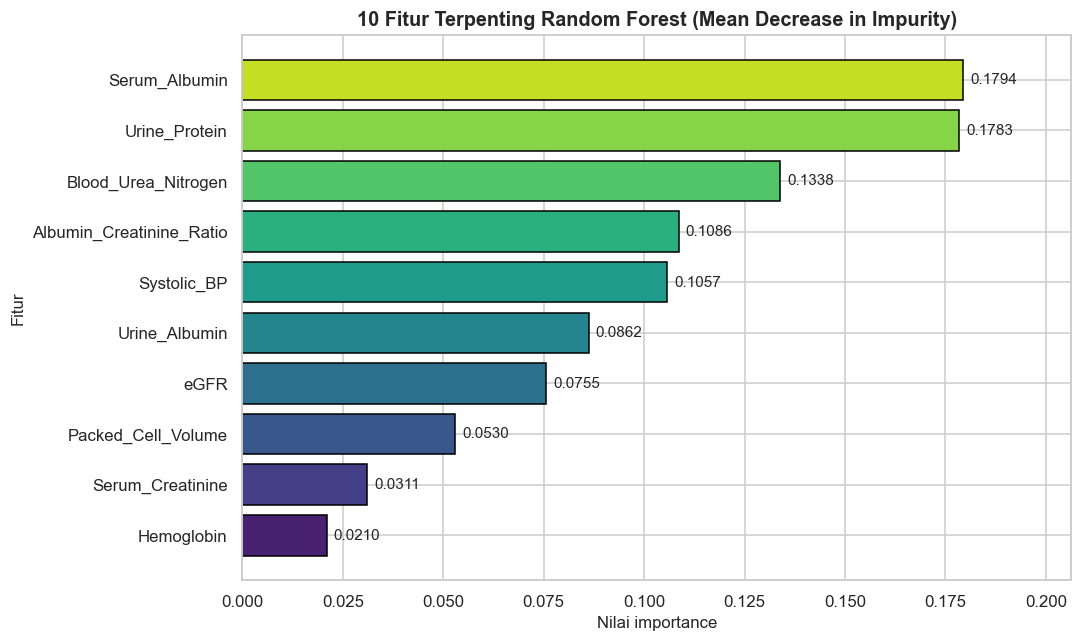

Importance dikelompokkan per fitur asal (35 fitur awal) — 10 teratas:


,importance
fitur_asal,
Serum_Albumin,0.1794
Urine_Protein,0.1783
Blood_Urea_Nitrogen,0.1338
Albumin_Creatinine_Ratio,0.1086
Systolic_BP,0.1057
Urine_Albumin,0.0862
eGFR,0.0755
Packed_Cell_Volume,0.0530
Serum_Creatinine,0.0311


In [29]:
top10 = fi.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
colors = sns.color_palette("viridis_r", 10)
ax.barh(top10["fitur"][::-1], top10["importance"][::-1], color=colors[::-1], edgecolor="black")
for i, v in enumerate(top10["importance"][::-1]):
    ax.text(v + top10["importance"].max() * 0.01, i, f"{v:.4f}", va="center", fontsize=10)
ax.set_title("10 Fitur Terpenting Random Forest (Mean Decrease in Impurity)")
ax.set_xlabel("Nilai importance")
ax.set_ylabel("Fitur")
ax.set_xlim(0, top10["importance"].max() * 1.15)
plt.tight_layout()
plt.show()

# Agregasi: gabungkan kolom one-hot kembali ke fitur asalnya (mis. Diabetes_Yes + Diabetes_No -> Diabetes)
def original_feature(name):
    for c in categorical_features:
        if name.startswith(c + "_"):
            return c
    return name
fi_agg = fi.assign(fitur_asal=fi["fitur"].map(original_feature)).groupby("fitur_asal")["importance"].sum().sort_values(ascending=False)
print("Importance dikelompokkan per fitur asal (35 fitur awal) — 10 teratas:")
display(fi_agg.head(10).round(4).rename("importance").to_frame())

In [30]:
# Interpretasi 10 fitur teratas: konteks klinis (data) + peringkat importance (hasil model)
clinical_notes = {
    "eGFR": "Estimasi laju filtrasi glomerulus; ukuran utama fungsi ginjal dan dasar penentuan stadium CKD (G1–G5).",
    "Serum_Creatinine": "Sisa metabolisme otot yang dibuang ginjal; naik saat filtrasi menurun, dan menjadi bahan hitung eGFR.",
    "Blood_Urea_Nitrogen": "Sisa metabolisme protein; menumpuk ketika fungsi filtrasi ginjal berkurang.",
    "Albumin_Creatinine_Ratio": "Penanda kerusakan ginjal (albuminuria); dipakai dalam klasifikasi risiko CKD menurut KDIGO.",
    "Urine_Albumin": "Albumin yang bocor ke urine; tanda kerusakan penyaring (glomerulus).",
    "Urine_Protein": "Protein di urine (proteinuria); tanda kerusakan ginjal.",
    "Urine_Specific_Gravity": "Kemampuan ginjal memekatkan urine; cenderung menurun pada gangguan ginjal.",
    "Hemoglobin": "Anemia sering menyertai CKD karena produksi eritropoietin menurun.",
    "Packed_Cell_Volume": "Hematokrit; ikut menurun pada anemia akibat CKD.",
    "RBC_Count": "Jumlah sel darah merah; berkaitan dengan anemia pada CKD.",
    "Potassium": "Elektrolit; gangguan (mis. hiperkalemia) umum pada CKD lanjut.",
    "Phosphorus": "Mineral; kadar naik saat ginjal gagal membuangnya (gangguan mineral-tulang CKD).",
    "Calcium": "Mineral; terganggu pada gangguan mineral-tulang CKD.",
    "Bicarbonate": "Penyangga asam-basa; rendah pada asidosis metabolik akibat CKD.",
    "Serum_Albumin": "Albumin darah; dapat menurun pada kehilangan protein lewat urine/malnutrisi.",
    "Total_Protein": "Protein total darah; terkait status gizi dan kehilangan protein.",
    "Sodium": "Elektrolit; keseimbangan cairan.", "Chloride": "Elektrolit; keseimbangan asam-basa.",
    "Age": "Faktor risiko: fungsi ginjal menurun seiring usia.",
    "Systolic_BP": "Tekanan darah; hipertensi merupakan penyebab sekaligus akibat CKD.",
    "Diastolic_BP": "Tekanan darah; berkaitan dengan beban pada pembuluh ginjal.",
    "HbA1c": "Kontrol gula darah jangka panjang; diabetes adalah penyebab utama CKD.",
    "Blood_Glucose_Random": "Gula darah sesaat; terkait diabetes.", "Fasting_Glucose": "Gula darah puasa; terkait diabetes.",
    "BMI": "Indeks massa tubuh; obesitas adalah faktor risiko.", "Cholesterol": "Profil lemak; terkait risiko kardiovaskular-ginjal.",
    "Triglycerides": "Profil lemak; terkait risiko kardiovaskular-ginjal.", "WBC_Count": "Penanda peradangan/infeksi non-spesifik.",
    "Platelet_Count": "Jumlah trombosit; non-spesifik untuk CKD.", "Heart_Rate": "Denyut jantung; non-spesifik untuk CKD.",
}
def note(name):
    base = original_feature(name)
    return clinical_notes.get(base, f"Faktor klinis/komorbid ({base}); interpretasi memerlukan konteks medis.")

interp = top10[["rank", "fitur", "importance"]].copy()
interp["konteks klinis"] = interp["fitur"].map(note)
pd.set_option("display.max_colwidth", 120)
display(interp.round(4))

direct = {"eGFR", "Serum_Creatinine", "Blood_Urea_Nitrogen", "Albumin_Creatinine_Ratio", "Urine_Albumin", "Urine_Protein"}
top10_orig = [original_feature(f) for f in top10["fitur"]]
n_direct = sum(f in direct for f in top10_orig)
share_top10 = top10["importance"].sum()
indirect = [f for f in top10_orig if f not in direct]
acc_now = accuracy_score(y_test, y_pred_test)

msg = (f"**Ringkasan:** 10 fitur teratas menyumbang **{share_top10:.1%}** dari total importance; "
       f"**{n_direct} dari 10** adalah penanda langsung fungsi/kerusakan ginjal (eGFR, kreatinin, BUN, ACR, albumin/protein urine), "
       f"sisanya ({', '.join('`'+f+'`' for f in indirect)}) adalah penanda komplikasi/komorbid. Fitur teratas: **`{top10.iloc[0]['fitur']}`** ({top10.iloc[0]['importance']:.4f}). "
       f"Secara umum penanda filtrasi dan kebocoran protein memang menentukan stadium CKD secara klinis. ")
if acc_now >= 0.999 and near_perfect:
    msg += (f"\n\n**⚠️ Peringatan interpretasi:** model mencapai akurasi {acc_now:.4f} dan {len(strong)} fitur masing-masing sudah sangat memisahkan kelas (bagian 9.1). "
            f"Ketika banyak fitur bisa saling menggantikan, MDI **membagi kredit secara hampir sewenang-wenang** di antara fitur-fitur redundan itu "
            f"(mis. fitur non-ginjal seperti {', '.join('`'+f+'`' for f in indirect[:2])} bisa tampak sangat penting). "
            f"Peringkat ini **tidak boleh dibaca sebagai kepentingan klinis**; periksa cek stabilitas di bawah. "
            f"Dan seperti biasa, importance = kepentingan **prediktif**, bukan bukti sebab-akibat.")
else:
    msg += "Ingat: importance adalah kepentingan *prediktif*, bukan bukti bahwa fitur tersebut *menyebabkan* penyakit."
display(Markdown(msg))

,rank,fitur,importance,konteks klinis
0,1,Serum_Albumin,0.1794,Albumin darah; dapat menurun pada kehilangan protein lewat urine/malnutrisi.
1,2,Urine_Protein,0.1783,Protein di urine (proteinuria); tanda kerusakan ginjal.
2,3,Blood_Urea_Nitrogen,0.1338,Sisa metabolisme protein; menumpuk ketika fungsi filtrasi ginjal berkurang.
3,4,Albumin_Creatinine_Ratio,0.1086,Penanda kerusakan ginjal (albuminuria); dipakai dalam klasifikasi risiko CKD menurut KDIGO.
4,5,Systolic_BP,0.1057,Tekanan darah; hipertensi merupakan penyebab sekaligus akibat CKD.
5,6,Urine_Albumin,0.0862,Albumin yang bocor ke urine; tanda kerusakan penyaring (glomerulus).
6,7,eGFR,0.0755,Estimasi laju filtrasi glomerulus; ukuran utama fungsi ginjal dan dasar penentuan stadium CKD (G1–G5).
7,8,Packed_Cell_Volume,0.0530,Hematokrit; ikut menurun pada anemia akibat CKD.
8,9,Serum_Creatinine,0.0311,"Sisa metabolisme otot yang dibuang ginjal; naik saat filtrasi menurun, dan menjadi bahan hitung eGFR."
9,10,Hemoglobin,0.0210,Anemia sering menyertai CKD karena produksi eritropoietin menurun.


**Ringkasan:** 10 fitur teratas menyumbang **97.3%** dari total importance; **6 dari 10** adalah penanda langsung fungsi/kerusakan ginjal (eGFR, kreatinin, BUN, ACR, albumin/protein urine), sisanya (`Serum_Albumin`, `Systolic_BP`, `Packed_Cell_Volume`, `Hemoglobin`) adalah penanda komplikasi/komorbid. Fitur teratas: **`Serum_Albumin`** (0.1794). Secara umum penanda filtrasi dan kebocoran protein memang menentukan stadium CKD secara klinis. 

**⚠️ Peringatan interpretasi:** model mencapai akurasi 1.0000 dan 9 fitur masing-masing sudah sangat memisahkan kelas (bagian 9.1). Ketika banyak fitur bisa saling menggantikan, MDI **membagi kredit secara hampir sewenang-wenang** di antara fitur-fitur redundan itu (mis. fitur non-ginjal seperti `Serum_Albumin`, `Systolic_BP` bisa tampak sangat penting). Peringkat ini **tidak boleh dibaca sebagai kepentingan klinis**; periksa cek stabilitas di bawah. Dan seperti biasa, importance = kepentingan **prediktif**, bukan bukti sebab-akibat.

### 15.1 Cek stabilitas feature importance

Importance dari model terbaik dibandingkan dengan **forest referensi** (500 pohon, `max_depth=None`, `random_state=42`). Jika peringkatnya berbeda jauh, berarti peringkat tersebut tidak stabil terhadap pilihan hiperparameter dan tidak layak ditafsirkan terlalu jauh.

,model_terbaik,referensi_500_pohon,rank_terbaik,rank_referensi
Serum_Albumin,0.1794,0.0775,1,9
Urine_Protein,0.1783,0.1166,2,1
Blood_Urea_Nitrogen,0.1338,0.1091,3,3
Albumin_Creatinine_Ratio,0.1086,0.1076,4,4
Systolic_BP,0.1057,0.1003,5,6
Urine_Albumin,0.0862,0.1035,6,5
eGFR,0.0755,0.0961,7,7
Packed_Cell_Volume,0.0530,0.0170,8,12
Serum_Creatinine,0.0311,0.0857,9,8
Hemoglobin,0.0210,0.0279,10,10


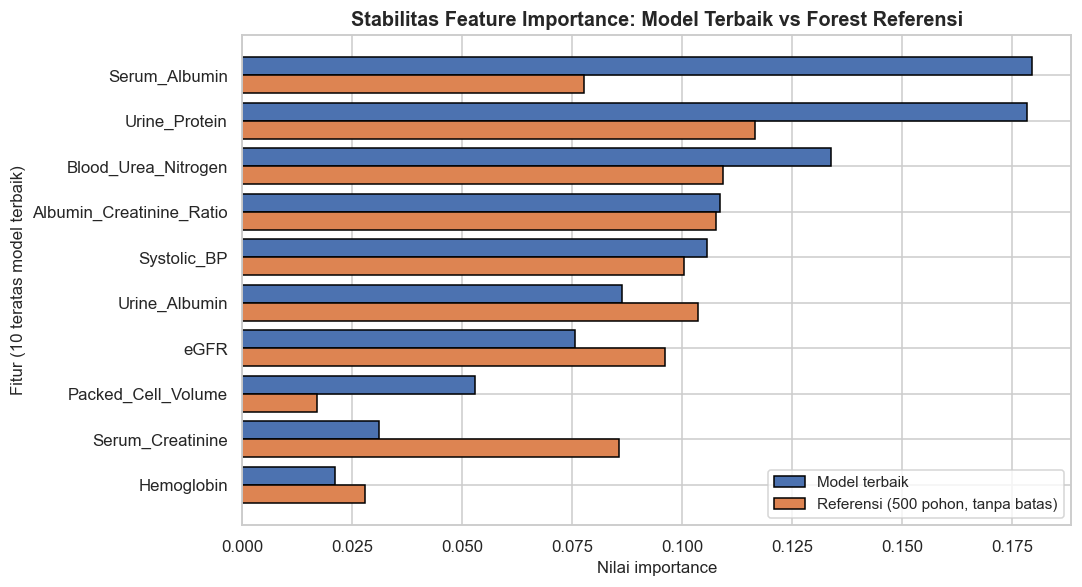

**Hasil:** 9 dari 10 fitur teratas sama pada kedua model; korelasi peringkat seluruh fitur (Spearman) = **0.833**. Peringkat **cukup berubah** antar konfigurasi: kepentingan fitur sebaiknya tidak ditafsirkan sebagai urutan pasti, terutama karena banyak fitur redundan yang dapat saling menggantikan.

In [31]:
ref_pipe = build_pipeline(n_estimators=500, max_depth=None).fit(X_train, y_train)
ref_names = [n.split("__", 1)[1] for n in ref_pipe.named_steps["preprocessor"].get_feature_names_out()]
ref_fi = pd.Series(ref_pipe.named_steps["model"].feature_importances_, index=ref_names)
cur_fi = pd.Series(importances, index=feature_names)

cmp_df = pd.DataFrame({"model_terbaik": cur_fi, "referensi_500_pohon": ref_fi})
cmp_df["rank_terbaik"] = cmp_df["model_terbaik"].rank(ascending=False, method="first").astype(int)
cmp_df["rank_referensi"] = cmp_df["referensi_500_pohon"].rank(ascending=False, method="first").astype(int)
top_cmp = cmp_df.sort_values("model_terbaik", ascending=False).head(10)
display(top_cmp.round(4))

overlap = len(set(cur_fi.nlargest(10).index) & set(ref_fi.nlargest(10).index))
rank_corr = cmp_df["model_terbaik"].rank().corr(cmp_df["referensi_500_pohon"].rank())   # korelasi peringkat (Spearman)

fig, ax = plt.subplots(figsize=(10, 5.5))
yy = np.arange(len(top_cmp))[::-1]
ax.barh(yy + 0.2, top_cmp["model_terbaik"], 0.4, label="Model terbaik", color="#4c72b0", edgecolor="black")
ax.barh(yy - 0.2, top_cmp["referensi_500_pohon"], 0.4, label="Referensi (500 pohon, tanpa batas)", color="#dd8452", edgecolor="black")
ax.set_yticks(yy); ax.set_yticklabels(top_cmp.index)
ax.set_title("Stabilitas Feature Importance: Model Terbaik vs Forest Referensi")
ax.set_xlabel("Nilai importance")
ax.set_ylabel("Fitur (10 teratas model terbaik)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

display(Markdown(
    f"**Hasil:** {overlap} dari 10 fitur teratas sama pada kedua model; korelasi peringkat seluruh fitur (Spearman) = **{rank_corr:.3f}**. "
    + ("Peringkat **relatif stabil**, namun tetap dibaca sebagai kepentingan prediktif." if overlap >= 8 and rank_corr >= 0.9 else
       "Peringkat **cukup berubah** antar konfigurasi: kepentingan fitur sebaiknya tidak ditafsirkan sebagai urutan pasti, "
       "terutama karena banyak fitur redundan yang dapat saling menggantikan.")))

## 16. Evaluasi Akhir Model

Model terbaik dievaluasi pada **data testing** yang tidak dipakai untuk pelatihan. Karena kelas tidak seimbang, ditampilkan:

- **Accuracy** dan **Balanced Accuracy** (rata-rata recall per kelas — tidak terpengaruh ukuran kelas).
- **Precision, Recall, F1-Score** per kelas.
- **Macro average** (semua kelas berbobot sama; sensitif terhadap kelas minoritas) dan **Weighted average** (berbobot jumlah sampel; didominasi kelas mayoritas).
- **Confusion Matrix** (jumlah dan proporsi per baris).

Seluruh angka berasal langsung dari hasil eksekusi model, tanpa penyesuaian.

In [32]:
# Ringkasan metrik global
summary = {
    "accuracy": accuracy_score(y_test, y_pred_test),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred_test),
    "precision_macro": precision_score(y_test, y_pred_test, average="macro"),
    "recall_macro": recall_score(y_test, y_pred_test, average="macro"),
    "f1_macro": f1_score(y_test, y_pred_test, average="macro"),
    "precision_weighted": precision_score(y_test, y_pred_test, average="weighted"),
    "recall_weighted": recall_score(y_test, y_pred_test, average="weighted"),
    "f1_weighted": f1_score(y_test, y_pred_test, average="weighted"),
}
display(pd.Series(summary, name="nilai").round(4).to_frame())

print("Classification Report (data testing):\n")
print(classification_report(y_test, y_pred_test, labels=CLASS_ORDER, digits=4))

# Tabel per kelas (precision, recall, F1, support)
p, r, f, s = precision_recall_fscore_support(y_test, y_pred_test, labels=CLASS_ORDER, zero_division=0)
per_class = pd.DataFrame({"precision": p, "recall": r, "f1-score": f, "support": s}, index=CLASS_ORDER)
display(per_class.round(4))

,nilai
accuracy,1.0
balanced_accuracy,1.0
precision_macro,1.0
recall_macro,1.0
f1_macro,1.0
precision_weighted,1.0
recall_weighted,1.0
f1_weighted,1.0


Classification Report (data testing):

                          precision    recall  f1-score   support

          Healthy Kidney     1.0000    1.0000    1.0000      3872
    Mild CKD (Stage 1–2)     1.0000    1.0000    1.0000       613
  Moderate CKD (Stage 3)     1.0000    1.0000    1.0000       361
    Severe CKD (Stage 4)     1.0000    1.0000    1.0000       211
Kidney Failure (Stage 5)     1.0000    1.0000    1.0000       103

                accuracy                         1.0000      5160
               macro avg     1.0000    1.0000    1.0000      5160
            weighted avg     1.0000    1.0000    1.0000      5160



,precision,recall,f1-score,support
Healthy Kidney,1.0,1.0,1.0,3872
Mild CKD (Stage 1–2),1.0,1.0,1.0,613
Moderate CKD (Stage 3),1.0,1.0,1.0,361
Severe CKD (Stage 4),1.0,1.0,1.0,211
Kidney Failure (Stage 5),1.0,1.0,1.0,103


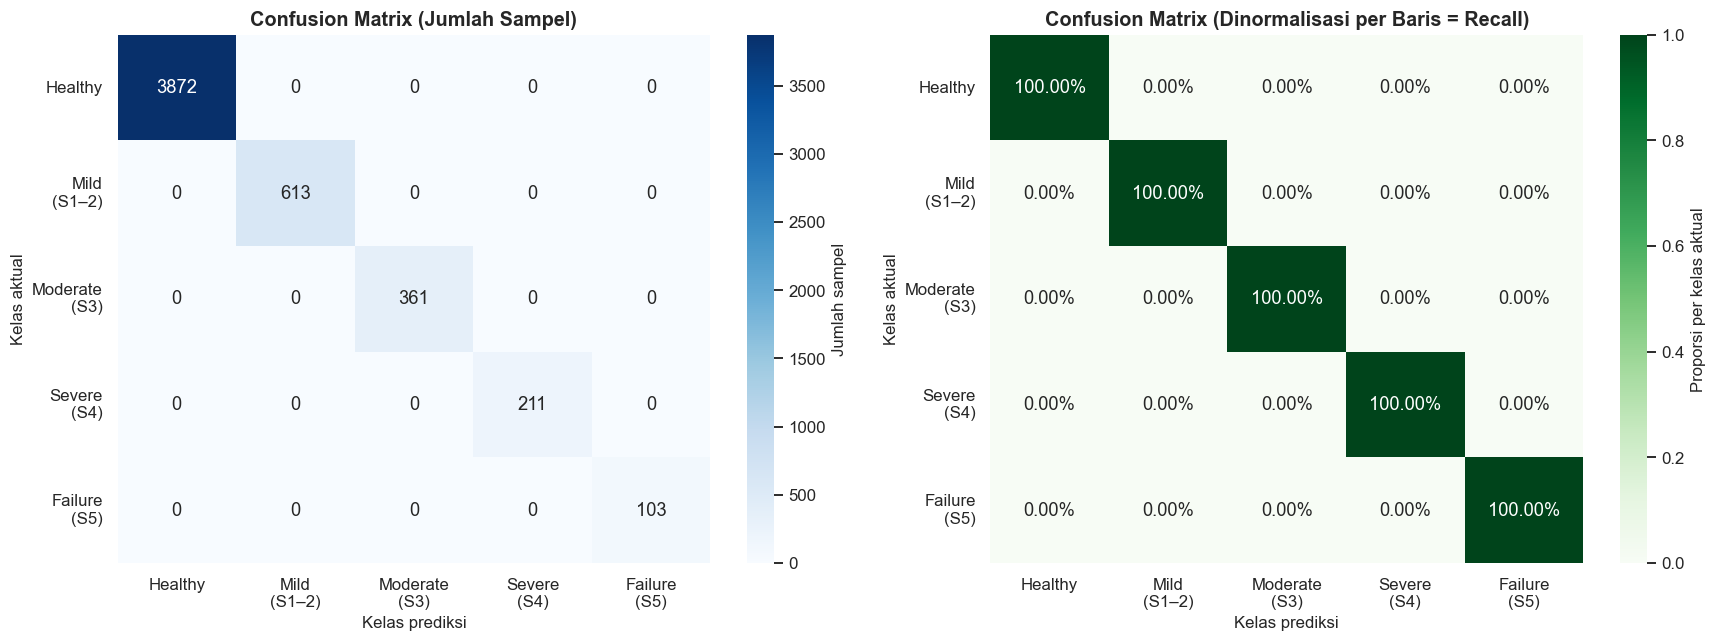

### Analisis otomatis evaluasi
- Accuracy **1.0000** vs baseline kelas mayoritas **0.7503**; balanced accuracy **1.0000**; macro F1 **1.0000** vs weighted F1 **1.0000**.
- Recall per kelas: Healthy = 1.000, Mild (S1–2) = 1.000, Moderate (S3) = 1.000, Severe (S4) = 1.000, Failure (S5) = 1.000.
- **Tidak ada satu pun salah klasifikasi** dari 5160 sampel uji; seluruh kelas, termasuk kelas paling jarang (**Kidney Failure (Stage 5)**, 103 sampel uji), memiliki recall dan F1 = 1,000. Karena tidak ada kesalahan, tidak ada kelas 'terlemah' maupun pola kebingungan antar-stadium yang bisa dianalisis.
- **⚠️ Skor sempurna bukan kabar baik tanpa konteks.** Hasil ini konsisten dengan temuan diagnostik 9.1 dan 14.1: kelas dapat dipisahkan sempurna oleh banyak fitur tunggal, sehingga tugas klasifikasinya *terlalu mudah* dan hasilnya hampir pasti tidak mencerminkan performa pada data klinis nyata.

In [33]:
# Confusion matrix: jumlah (kiri) dan proporsi per baris = recall per kelas (kanan)
cm = confusion_matrix(y_test, y_pred_test, labels=CLASS_ORDER)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
labels_short = [SHORT_LABEL[c] for c in CLASS_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_short, yticklabels=labels_short,
            cbar_kws={"label": "Jumlah sampel"}, ax=axes[0])
axes[0].set_title("Confusion Matrix (Jumlah Sampel)")
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", xticklabels=labels_short, yticklabels=labels_short,
            vmin=0, vmax=1, cbar_kws={"label": "Proporsi per kelas aktual"}, ax=axes[1])
axes[1].set_title("Confusion Matrix (Dinormalisasi per Baris = Recall)")
for ax in axes:
    ax.set_xlabel("Kelas prediksi")
    ax.set_ylabel("Kelas aktual")
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

# ----- Analisis otomatis -----
recall_per_class = pd.Series(r, index=CLASS_ORDER)
f1_per_class = pd.Series(f, index=CLASS_ORDER)
weakest = recall_per_class.idxmin()
off = sorted([(CLASS_ORDER[i], CLASS_ORDER[j], int(cm[i, j])) for i in range(5) for j in range(5) if i != j and cm[i, j] > 0], key=lambda t: -t[2])[:3]
n_err = int(cm.sum() - np.trace(cm))
adjacent_err = int(sum(cm[i, j] for i in range(5) for j in range(5) if i != j and abs(i - j) == 1))
perfect = n_err == 0

lines = ["### Analisis otomatis evaluasi",
         f"- Accuracy **{summary['accuracy']:.4f}** vs baseline kelas mayoritas **{baseline_acc:.4f}**; balanced accuracy **{summary['balanced_accuracy']:.4f}**; "
         f"macro F1 **{summary['f1_macro']:.4f}** vs weighted F1 **{summary['f1_weighted']:.4f}**.",
         "- Recall per kelas: " + ", ".join(f"{SHORT_LABEL[c].replace(chr(10), ' ')} = {v:.3f}" for c, v in recall_per_class.items()) + "."]
if perfect:
    lines += [f"- **Tidak ada satu pun salah klasifikasi** dari {int(cm.sum())} sampel uji; seluruh kelas, termasuk kelas paling jarang "
              f"(**{CLASS_ORDER[-1]}**, {int(per_class.loc[CLASS_ORDER[-1], 'support'])} sampel uji), memiliki recall dan F1 = 1,000. "
              f"Karena tidak ada kesalahan, tidak ada kelas 'terlemah' maupun pola kebingungan antar-stadium yang bisa dianalisis.",
              "- **⚠️ Skor sempurna bukan kabar baik tanpa konteks.** Hasil ini konsisten dengan temuan diagnostik 9.1 dan 14.1: kelas dapat dipisahkan "
              "sempurna oleh banyak fitur tunggal, sehingga tugas klasifikasinya *terlalu mudah* dan hasilnya hampir pasti tidak mencerminkan performa pada data klinis nyata."]
else:
    lines += [f"- Kelas dengan recall terendah: **{weakest}** (recall {recall_per_class.min():.3f}, F1 {f1_per_class[weakest]:.3f}, support {int(per_class.loc[weakest,'support'])}).",
              f"- Total salah klasifikasi: **{n_err}** dari {int(cm.sum())}; **{adjacent_err}** ({adjacent_err / max(n_err, 1):.0%}) terjadi antar-stadium bersebelahan.",
              "- Kesalahan paling sering (aktual -> prediksi): " + "; ".join(f"{a_} -> {b_} ({n_}x)" for a_, b_, n_ in off) + "."]
display(Markdown("\n".join(lines)))

## 17. Business Insight

Bagian ini menafsirkan hasil dalam konteks kesehatan. Poin 1–3 disusun otomatis dari hasil eksekusi agar selalu konsisten dengan angka yang sebenarnya; poin 4–5 dan keterbatasan bersifat umum.

In [34]:
top5_agg = ", ".join(f"`{n}`" for n in fi_agg.head(5).index)
egfr_rng = df.groupby("Target")["eGFR"].agg(["min", "max"]).reindex(CLASS_ORDER)
egfr_txt = "; ".join(f"{SHORT_LABEL[c].replace(chr(10), ' ')} {int(egfr_rng.loc[c,'min'])}–{int(egfr_rng.loc[c,'max'])}" for c in CLASS_ORDER)

bi = ["**1. Fitur apa yang paling berpengaruh dalam klasifikasi?**",
      f"Lima fitur asal dengan importance tertinggi: {top5_agg}. Penanda fungsi/kerusakan ginjal (eGFR, kreatinin, BUN, ACR, albumin/protein urine) "
      f"memang secara klinis menentukan stadium CKD. Namun karena fitur-fitur ini sangat dekat dengan definisi stadium dan banyak fitur lain saling menggantikan "
      f"(bagian 9.1, 14.1, 15.1), peringkat importance **bukan temuan faktor risiko baru** dan **bukan bukti sebab-akibat**.",
      "",
      "**2. Bagaimana model membedakan Healthy Kidney dan stadium CKD?**"]
if perfect:
    bi.append(f"Pada data uji, model memisahkan kelima kelas **tanpa kesalahan**. Penyebabnya terlihat pada data: rentang eGFR per kelas tidak tumpang tindih sama sekali "
              f"({egfr_txt}), demikian pula banyak fitur lain. Model cukup mempelajari ambang-ambang tersebut. Pada pasien nyata, nilai laboratorium di perbatasan stadium "
              f"hampir selalu bertumpang tindih dan bervariasi antar waktu pengukuran, sehingga performa sempurna seperti ini **tidak dapat diharapkan** di praktik.")
else:
    bi.append(f"Model memisahkan kelas dengan accuracy {summary['accuracy']:.4f}; {adjacent_err} dari {n_err} kesalahan terjadi antar-stadium bersebelahan, "
              f"wajar karena nilai laboratorium di perbatasan stadium saling tumpang tindih.")
bi += ["",
       "**3. Apa arti kesalahan klasifikasi pada kelas yang lebih berat?**",
       f"Kesalahan **tidak setara**. *False negative* pada stadium berat (mis. Stage 4–5 diprediksi lebih ringan) berisiko menunda rujukan dan persiapan terapi pengganti ginjal; "
       f"*false positive* (diprediksi lebih berat) cenderung berujung pada pemeriksaan tambahan yang lebih mudah dikoreksi. Karena itu recall kelas penyakit lebih penting daripada accuracy keseluruhan — "
       f"contohnya pada Skenario B, `max_depth=3` tetap memiliki accuracy {shallow['test_acc']:.2%} padahal recall kelas **{worst_cls3}** hanya "
       f"{np.asarray(shallow['recall_by_class']).min():.2f}: kelas yang paling berbahaya bila terlewat justru bisa 'hilang' di balik accuracy yang tampak tinggi."]
display(Markdown("\n".join(bi)))

**1. Fitur apa yang paling berpengaruh dalam klasifikasi?**
Lima fitur asal dengan importance tertinggi: `Serum_Albumin`, `Urine_Protein`, `Blood_Urea_Nitrogen`, `Albumin_Creatinine_Ratio`, `Systolic_BP`. Penanda fungsi/kerusakan ginjal (eGFR, kreatinin, BUN, ACR, albumin/protein urine) memang secara klinis menentukan stadium CKD. Namun karena fitur-fitur ini sangat dekat dengan definisi stadium dan banyak fitur lain saling menggantikan (bagian 9.1, 14.1, 15.1), peringkat importance **bukan temuan faktor risiko baru** dan **bukan bukti sebab-akibat**.

**2. Bagaimana model membedakan Healthy Kidney dan stadium CKD?**
Pada data uji, model memisahkan kelima kelas **tanpa kesalahan**. Penyebabnya terlihat pada data: rentang eGFR per kelas tidak tumpang tindih sama sekali (Healthy 90–119; Mild (S1–2) 60–89; Moderate (S3) 30–59; Severe (S4) 15–29; Failure (S5) 5–14), demikian pula banyak fitur lain. Model cukup mempelajari ambang-ambang tersebut. Pada pasien nyata, nilai laboratorium di perbatasan stadium hampir selalu bertumpang tindih dan bervariasi antar waktu pengukuran, sehingga performa sempurna seperti ini **tidak dapat diharapkan** di praktik.

**3. Apa arti kesalahan klasifikasi pada kelas yang lebih berat?**
Kesalahan **tidak setara**. *False negative* pada stadium berat (mis. Stage 4–5 diprediksi lebih ringan) berisiko menunda rujukan dan persiapan terapi pengganti ginjal; *false positive* (diprediksi lebih berat) cenderung berujung pada pemeriksaan tambahan yang lebih mudah dikoreksi. Karena itu recall kelas penyakit lebih penting daripada accuracy keseluruhan — contohnya pada Skenario B, `max_depth=3` tetap memiliki accuracy 98.00% padahal recall kelas **Kidney Failure (Stage 5)** hanya 0.00: kelas yang paling berbahaya bila terlewat justru bisa 'hilang' di balik accuracy yang tampak tinggi.

**4. Bagaimana feature importance membantu memahami pola data?**
Importance memberi gambaran awal penanda mana yang paling banyak dipakai model, membantu memeriksa apakah model bertumpu pada alasan yang masuk akal secara klinis, dan memprioritaskan pemeriksaan laboratorium untuk ditelaah lebih lanjut. Ia menunjukkan **kepentingan prediktif, bukan sebab-akibat**, dan perlu diuji kestabilannya (15.1).

**5. Bagaimana model dapat menjadi alat bantu analisis awal?**
Sebagai bahan pembelajaran dan prototipe alur *skrining/triase awal* (menandai profil laboratorium yang mengarah ke stadium tertentu untuk ditinjau tenaga medis), serta sebagai contoh bagaimana pipeline ML dibangun dan dievaluasi dengan benar.

**Keterbatasan yang perlu diingat**
- Dataset memperlihatkan **keterpisahan kelas yang tidak realistis** (banyak fitur tunggal memberi akurasi ~100%), mengindikasikan data sintetis atau label turunan fitur. Model belum divalidasi pada data klinis nyata atau secara eksternal.
- Risiko *target leakage* konseptual pada `eGFR`/`Serum_Creatinine` (dan penanda lain) — performa tinggi tidak mencerminkan kemampuan prediksi independen.
- Kelas minoritas (Stage 4 dan 5) hanya memiliki 211 dan 103 sampel uji sehingga estimasi recall-nya kurang stabil.
- Pemilihan hiperparameter memakai data testing (sesuai ketentuan tugas), sehingga estimasi akhir cenderung optimis.

> ⚠️ **Model ini adalah alat bantu penelitian dan edukasi, BUKAN pengganti diagnosis atau keputusan dokter.**

## 18. Kesimpulan

Kesimpulan di bawah ini disusun otomatis dari hasil eksekusi di atas, sehingga selalu sesuai dengan angka yang sebenarnya.

In [35]:
top3 = ", ".join(f"`{n}`" for n in fi["fitur"].head(3))
sat = summary["accuracy"] >= 0.999
items = []
if sat and near_perfect:
    items.append(f"**⚠️ Temuan utama:** model mencapai accuracy **{summary['accuracy']:.4f}** pada data uji, tetapi hasil ini **bukan indikator kualitas klinis**. "
                 f"{len(near_perfect)} fitur masing-masing sudah memberi akurasi >= 99,9% sendirian, dan akurasi masih {sens['accuracy'].min():.4f} walau {int(sens['fitur_dibuang'].max())} fitur utama dibuang. "
                 f"Pola ini mengindikasikan label ditentukan oleh rentang nilai fitur yang tidak tumpang tindih (data sintetis atau label turunan fitur), sehingga tugas klasifikasi ini terlalu mudah.")
if spread_A < 1e-9:
    items.append(f"**Jumlah pohon (Skenario A):** akurasi testing identik (**{results_A.iloc[0]['test_acc']:.4f}**) pada 10–500 pohon; menambah pohon hanya menambah waktu "
                 f"(±{results_A.iloc[-1]['fit_sec'] / results_A.iloc[0]['fit_sec']:.0f}x). Terpilih **n_estimators = {best_n}** berdasarkan aturan pemilihan (log loss lalu kesederhanaan).")
else:
    items.append(f"**Jumlah pohon (Skenario A):** akurasi testing {results_A.iloc[0]['test_acc']:.4f} (10 pohon) -> {results_A.iloc[-1]['test_acc']:.4f} (500 pohon); terpilih **n_estimators = {best_n}**.")
items.append(f"**Kedalaman pohon (Skenario B):** `max_depth=3` mengalami underfitting (recall kelas **{worst_cls3}** = {np.asarray(shallow['recall_by_class']).min():.2f}, balanced accuracy {shallow['test_bal_acc']:.3f}) "
             f"meski accuracy {shallow['test_acc']:.3f}; kedalaman >= 5 tidak berbeda karena pohon berhenti tumbuh di kedalaman maksimum {free_depth}. Terpilih **max_depth = {best_depth_label}**. Tidak ditemukan indikasi overfitting (gap <= {results_B['gap'].abs().max():.4f}).")
items.append(f"**Model final:** Random Forest (n_estimators={best_n}, max_depth={best_depth_label}); accuracy **{summary['accuracy']:.4f}**, balanced accuracy **{summary['balanced_accuracy']:.4f}**, "
             f"macro F1 **{summary['f1_macro']:.4f}**, weighted F1 **{summary['f1_weighted']:.4f}** (baseline kelas mayoritas {baseline_acc:.4f}); {n_err} salah klasifikasi dari {int(cm.sum())} sampel uji.")
items.append(f"**Fitur terpenting:** {top3}. Ini kepentingan prediktif (bukan sebab-akibat); stabilitas peringkat: {overlap}/10 fitur teratas sama dengan forest referensi (Spearman {rank_corr:.2f}).")
items.append("**Alat bantu penelitian/edukasi**, bukan pengganti diagnosis atau keputusan dokter. Untuk penelitian lanjutan: gunakan data klinis nyata dengan label independen dari fitur, "
             "validasi hiperparameter dengan cross-validation, dan evaluasi eksternal.")
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(items, 1))))

1. **⚠️ Temuan utama:** model mencapai accuracy **1.0000** pada data uji, tetapi hasil ini **bukan indikator kualitas klinis**. 6 fitur masing-masing sudah memberi akurasi >= 99,9% sendirian, dan akurasi masih 0.9762 walau 9 fitur utama dibuang. Pola ini mengindikasikan label ditentukan oleh rentang nilai fitur yang tidak tumpang tindih (data sintetis atau label turunan fitur), sehingga tugas klasifikasi ini terlalu mudah.
2. **Jumlah pohon (Skenario A):** akurasi testing identik (**1.0000**) pada 10–500 pohon; menambah pohon hanya menambah waktu (±6x). Terpilih **n_estimators = 10** berdasarkan aturan pemilihan (log loss lalu kesederhanaan).
3. **Kedalaman pohon (Skenario B):** `max_depth=3` mengalami underfitting (recall kelas **Kidney Failure (Stage 5)** = 0.00, balanced accuracy 0.800) meski accuracy 0.980; kedalaman >= 5 tidak berbeda karena pohon berhenti tumbuh di kedalaman maksimum 5. Terpilih **max_depth = 5**. Tidak ditemukan indikasi overfitting (gap <= 0.0000).
4. **Model final:** Random Forest (n_estimators=10, max_depth=5); accuracy **1.0000**, balanced accuracy **1.0000**, macro F1 **1.0000**, weighted F1 **1.0000** (baseline kelas mayoritas 0.7503); 0 salah klasifikasi dari 5160 sampel uji.
5. **Fitur terpenting:** `Serum_Albumin`, `Urine_Protein`, `Blood_Urea_Nitrogen`. Ini kepentingan prediktif (bukan sebab-akibat); stabilitas peringkat: 9/10 fitur teratas sama dengan forest referensi (Spearman 0.83).
6. **Alat bantu penelitian/edukasi**, bukan pengganti diagnosis atau keputusan dokter. Untuk penelitian lanjutan: gunakan data klinis nyata dengan label independen dari fitur, validasi hiperparameter dengan cross-validation, dan evaluasi eksternal.

## 19. Penyimpanan Model

Yang disimpan adalah **seluruh `Pipeline`** (imputer + one-hot encoder + Random Forest) dengan `joblib`, bukan hanya estimator-nya. Dengan begitu data baru cukup berformat kolom sama seperti data mentah — preprocessing dijalankan otomatis. Metadata disimpan sebagai JSON (termasuk ringkasan seluruh hasil eksperimen). Dataset asli tidak diubah.

In [36]:
MODEL_DIR.mkdir(exist_ok=True)
MODEL_PATH = MODEL_DIR / "random_forest_ckd.pkl"
META_PATH = MODEL_DIR / "model_metadata.json"

joblib.dump(best_pipeline, MODEL_PATH, compress=3)

def to_native(d):
    # Ubah nilai numpy menjadi tipe Python biasa agar dapat disimpan sebagai JSON
    return {k: (float(v) if isinstance(v, (np.floating, float)) else v) for k, v in d.items()}

metadata = {
    "algorithm": "RandomForestClassifier (scikit-learn) dalam Pipeline (SimpleImputer + OneHotEncoder + RandomForest)",
    "dataset": DATA_PATH.name,
    "n_rows": int(df.shape[0]),
    "n_features_initial": int(X.shape[1]),
    "n_features_after_encoding": int(len(feature_names)),
    "n_target_classes": int(y.nunique()),
    "target_classes": CLASS_ORDER,
    "best_n_estimators": int(best_n),
    "best_max_depth": best_depth,                 # None disimpan sebagai null
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "evaluation_metrics_test": to_native(summary),
    "per_class_test": {c: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i])}
                       for i, c in enumerate(CLASS_ORDER)},
    "training_accuracy": float(accuracy_score(y_train, y_pred_train)),
    "baseline_majority_accuracy": float(baseline_acc),
    "top10_feature_importance": {row.fitur: float(row.importance) for row in top10.itertuples()},
    "scenario_A_n_estimators": json.loads(results_A.drop(columns="recall_by_class").round(6).to_json(orient="records")),
    "scenario_B_max_depth": json.loads(results_B.drop(columns=["diagnosis", "recall_by_class"]).round(6).to_json(orient="records")),
    "single_feature_diagnostic_near_perfect": near_perfect,
    "sensitivity_analysis": json.loads(sens.round(6).to_json(orient="records")),
    "leakage_note": ("PERINGATAN: label dapat direkonstruksi dari banyak fitur tunggal (eGFR, Serum_Creatinine, ACR, protein/albumin urine, BUN, "
                     "tekanan darah) dan akurasi tetap tinggi walau fitur tersebut dibuang; indikasi keterpisahan sempurna/data sintetis. "
                     "Skor evaluasi tidak mencerminkan performa klinis nyata. Lihat notebook bagian 8.2, 9.1, 14.1."),
    "disclaimer": "Alat bantu penelitian dan edukasi; bukan pengganti diagnosis atau keputusan dokter.",
    "sklearn_version": sklearn.__version__,
    "training_date": datetime.now().isoformat(timespec="seconds"),
}
with open(META_PATH, "w", encoding="utf-8") as fh:
    json.dump(metadata, fh, ensure_ascii=False, indent=2)

print(f"Model    : {MODEL_PATH.relative_to(BASE_DIR)}  ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print(f"Metadata : {META_PATH.relative_to(BASE_DIR)}")

Model    : model\random_forest_ckd.pkl  (0.0 MB)
Metadata : model\model_metadata.json


In [37]:
# ----- Verifikasi: muat ulang model dan pakai untuk memprediksi data baru -----
loaded_model = joblib.load(MODEL_PATH)

# 1) Prediksi model termuat harus identik dengan model di memori
same = (loaded_model.predict(X_test) == y_pred_test).all()
print("Prediksi model termuat identik dengan model asli pada seluruh data testing:", bool(same))

# 2) Contoh 'data baru' dengan format kolom yang sama
new_data = X_test.head(5).copy()
result = pd.DataFrame({"prediksi": loaded_model.predict(new_data), "aktual": y_test.head(5).values})
proba = loaded_model.predict_proba(new_data)
result["confidence"] = proba.max(axis=1).round(3)
display(result)

# 3) Ketahanan: data baru dengan nilai kosong dan kategori yang belum pernah dilihat
robust = new_data.copy()
robust.iloc[0, robust.columns.get_loc("eGFR")] = np.nan
robust.iloc[1, robust.columns.get_loc("Diabetes")] = np.nan
robust.iloc[2, robust.columns.get_loc("Smoking_Status")] = "Unknown"
print("Prediksi pada data dengan nilai kosong / kategori baru:", loaded_model.predict(robust).tolist())

# 4) Dataset asli tidak diubah
print("Dataset asli tetap utuh:", pd.read_csv(DATA_PATH).shape == df.shape)

Prediksi model termuat identik dengan model asli pada seluruh data testing: True


,prediksi,aktual,confidence
0,Kidney Failure (Stage 5),Kidney Failure (Stage 5),1.0
1,Mild CKD (Stage 1–2),Mild CKD (Stage 1–2),1.0
2,Mild CKD (Stage 1–2),Mild CKD (Stage 1–2),1.0
3,Healthy Kidney,Healthy Kidney,1.0
4,Healthy Kidney,Healthy Kidney,1.0


Prediksi pada data dengan nilai kosong / kategori baru: ['Kidney Failure (Stage 5)', 'Mild CKD (Stage 1–2)', 'Mild CKD (Stage 1–2)', 'Healthy Kidney', 'Healthy Kidney']
Dataset asli tetap utuh: True


---
### Cara menjalankan ulang
1. Pastikan struktur folder: `data/raw_CKD_dataset.csv`, `model/`, `notebook/`.
2. Instal dependensi: `pip install pandas numpy scikit-learn matplotlib seaborn joblib jupyter`.
3. Buka `notebook/TA06_Random_Forest_CKD.ipynb` lalu **Run All**.
4. Untuk memakai model: `joblib.load("model/random_forest_ckd.pkl").predict(data_baru)` dengan kolom yang sama seperti data mentah (tanpa `Target`).